In [1]:
%pip install pandas numpy matplotlib seaborn mlxtend openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "../data/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

# Path to the PaySim dataset inside our project folder
file_path = "../data/PS_20174392719_1491204439457_log.csv"

# Load the CSV file into a Pandas DataFrame
df = pd.read_csv(file_path)

# Display basic information about the dataset
print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully.
Number of rows: 6362620
Number of columns: 11


In [4]:
# Display the first five transactions to understand the data
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
# ============================================================
# 3. DATA UNDERSTANDING
# ============================================================

# Display column names and their data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [6]:
# Display the total number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (6362620, 11)


In [7]:
# List all columns available in the dataset
print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [8]:
# Generate descriptive statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


In [9]:
# ============================================================
# 4. DATA QUALITY CHECK
# ============================================================

# Count missing values in every column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [10]:
# Check whether any complete duplicate transaction records exist
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [11]:
# ============================================================
# 5. FRAUD DISTRIBUTION
# ============================================================

# Count fraudulent and non-fraudulent transactions
fraud_counts = df["isFraud"].value_counts()

print("Transaction distribution:")
print(fraud_counts)

Transaction distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [12]:
# Calculate the percentage of fraudulent and non-fraudulent transactions
fraud_percentage = df["isFraud"].value_counts(normalize=True) * 100

print("Transaction percentage:")
print(fraud_percentage)

Transaction percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


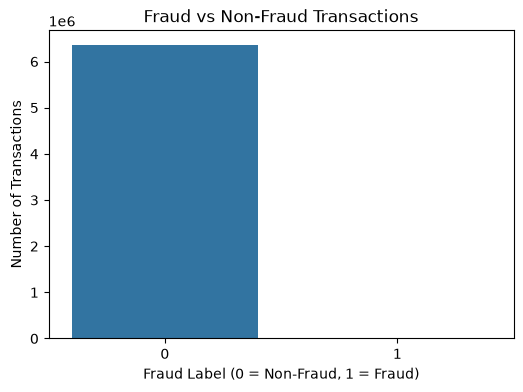

In [13]:
# Plot the distribution of fraudulent vs non-fraudulent transactions
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="isFraud")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud Label (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [14]:
# ============================================================
# 6. TRANSACTION TYPE ANALYSIS
# ============================================================

# Count the number of transactions for each transaction type
transaction_types = df["type"].value_counts()

print("Transaction types:")
print(transaction_types)

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


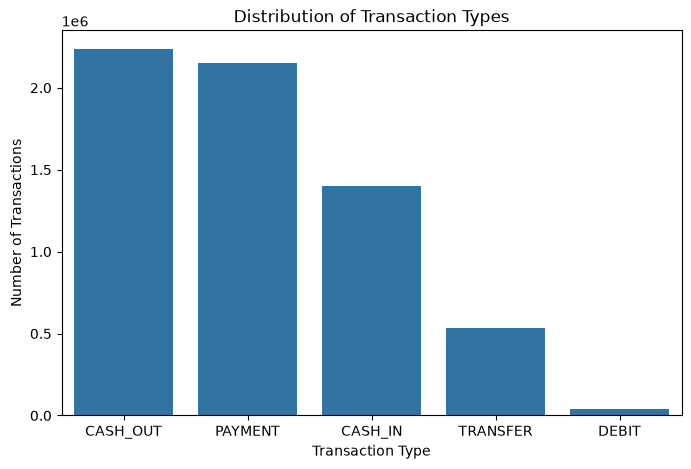

In [15]:
# Plot the distribution of different transaction types
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type", order=df["type"].value_counts().index)

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

### Observation

The dataset is highly imbalanced, with approximately 99.87% non-fraudulent
transactions and 0.13% fraudulent transactions. Therefore, fraud-associated
patterns represent a small portion of the overall transaction population.

This class imbalance must be considered when evaluating association rules.
Confidence alone may be misleading, so support and lift will also be used to
evaluate the strength and usefulness of discovered fraud patterns.

In [16]:
# ============================================================
# 7. FRAUD ANALYSIS BY TRANSACTION TYPE
# ============================================================

# Count fraudulent transactions for each transaction type
fraud_by_type = df[df["isFraud"] == 1]["type"].value_counts()

print("Fraudulent transactions by type:")
print(fraud_by_type)

Fraudulent transactions by type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [17]:
# Calculate the fraud rate within each transaction type
fraud_rate_by_type = df.groupby("type")["isFraud"].mean() * 100

print("Fraud rate by transaction type:")
print(fraud_rate_by_type.sort_values(ascending=False))

Fraud rate by transaction type:
type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


### Observation

Fraudulent transactions occur only in the TRANSFER and CASH_OUT transaction
types in the dataset. TRANSFER has the highest fraud rate (approximately
0.77%), followed by CASH_OUT (approximately 0.18%).

CASH_IN, DEBIT and PAYMENT transactions contain no fraudulent transactions
in this dataset.

Therefore, the subsequent fraud-pattern analysis will focus on TRANSFER and
CASH_OUT transactions. This reduces the search space for association mining
while retaining all fraudulent transactions.

In [18]:
# ============================================================
# 8. CREATE FRAUD ANALYSIS DATASET
# ============================================================

# Keep the original dataset unchanged.
# Create a separate dataframe containing only transaction types
# that contain fraudulent transactions.

arm_df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

print("Original dataset shape:", df.shape)
print("Fraud analysis dataset shape:", arm_df.shape)
print("\nFraud distribution:")
print(arm_df["isFraud"].value_counts())

Original dataset shape: (6362620, 11)
Fraud analysis dataset shape: (2770409, 11)

Fraud distribution:
isFraud
0    2762196
1       8213
Name: count, dtype: int64


In [19]:
# Examine transaction amount statistics for the selected transaction types
arm_df.groupby("type")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
CASH_OUT,2237500.0,176273.964346,1.753297e+05,0.0,72669.65,147072.185,246539.4775,10000000.00
TRANSFER,532909.0,910647.009645,1.879574e+06,2.6,215905.35,486308.390,974958.0000,92445516.64


In [20]:
# Compare transaction amounts between fraud and non-fraud transactions
arm_df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,2762196.0,3.141155e+05,8.771441e+05,0.01,82908.2325,171034.46,305994.185,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.3300,441423.44,1517771.480,10000000.00


In [21]:
# ============================================================
# 9. AMOUNT FEATURE ENGINEERING
# ============================================================

# Create separate amount categories for each transaction type.
# Quantiles are calculated within each type so that CASH_OUT
# and TRANSFER transactions are compared fairly.

def create_amount_category(group):
    # Divide transactions into 4 groups based on their amount:
    # LOW, MEDIUM, HIGH and VERY_HIGH
    return pd.qcut(
        group["amount"],
        q=4,
        labels=["LOW", "MEDIUM", "HIGH", "VERY_HIGH"],
        duplicates="drop"
    )


# Apply the categorization separately to CASH_OUT and TRANSFER
arm_df["amount_category"] = (
    arm_df.groupby("type", group_keys=False)
    .apply(create_amount_category, include_groups=False)
    .reset_index(level=0, drop=True)
)

# Add a clear prefix for use as FP-Growth items
arm_df["amount_category"] = (
    "AMOUNT_" + arm_df["amount_category"].astype(str)
)

# Display the distribution
print("Amount category distribution:")
print(arm_df["amount_category"].value_counts())

Amount category distribution:
amount_category
AMOUNT_MEDIUM       304988
AMOUNT_LOW          304692
AMOUNT_HIGH         304449
AMOUNT_VERY_HIGH    304390
Name: count, dtype: int64


In [22]:
# ============================================================
# 10. BALANCE CHANGE FEATURE
# ============================================================

# Calculate the change in the origin account balance.
# A positive value means money decreased after the transaction.
arm_df["balance_change"] = (
    arm_df["oldbalanceOrg"] - arm_df["newbalanceOrig"]
)

# Examine balance-change statistics for fraud and non-fraud
balance_change_stats = arm_df.groupby("isFraud")["balance_change"].describe()

print("Balance change statistics:")
print(balance_change_stats)

Balance change statistics:
             count          mean           std       min        25%  \
isFraud                                                               
0        2762196.0  2.731199e+04  6.146932e+04 -26575.26       0.00   
1           8213.0  1.457275e+06  2.396099e+06      0.00  124582.58   

               50%         75%          max  
isFraud                                      
0           278.00    26149.00   4164236.31  
1        436317.49  1503034.86  10000000.00  


In [23]:
# Compare the transaction amount with the actual balance change
# for fraudulent and non-fraudulent transactions.

arm_df["amount_balance_difference"] = (
    arm_df["amount"] - arm_df["balance_change"]
)

print("Amount vs balance-change difference:")
print(
    arm_df.groupby("isFraud")["amount_balance_difference"].describe()
)

Amount vs balance-change difference:
             count           mean            std           min       25%  \
isFraud                                                                    
0        2762196.0  286803.509954  876375.192156 -1.000000e-02  52613.43   
1           8213.0   10692.325265  265146.131130 -3.725290e-09      0.00   

                50%         75%          max  
isFraud                                       
0        144200.825  280466.255  92445516.64  
1             0.000       0.000  10000000.00  


In [24]:
# ============================================================
# 11. BALANCE CHANGE CATEGORIZATION
# ============================================================

# Convert the numerical balance change into four categories.
# Quantile-based categories avoid choosing arbitrary rupee thresholds.

arm_df["balance_change_category"] = pd.qcut(
    arm_df["balance_change"],
    q=4,
    labels=[
        "LOW",
        "MEDIUM",
        "HIGH",
        "VERY_HIGH"
    ],
    duplicates="drop"
)

# Add a prefix so this feature becomes a clear FP-Growth item
arm_df["balance_change_category"] = (
    "BALANCE_CHANGE_" +
    arm_df["balance_change_category"].astype(str)
)

# Display the distribution
print("Balance change category distribution:")
print(arm_df["balance_change_category"].value_counts())

Balance change category distribution:
balance_change_category
BALANCE_CHANGE_LOW          1308603
BALANCE_CHANGE_VERY_HIGH     692602
BALANCE_CHANGE_HIGH          692462
BALANCE_CHANGE_MEDIUM         76742
Name: count, dtype: int64


In [25]:
# Check how fraud is distributed across balance-change categories

fraud_balance_pattern = pd.crosstab(
    arm_df["balance_change_category"],
    arm_df["isFraud"],
    normalize="index"
) * 100

print("Fraud percentage within each balance-change category:")
print(fraud_balance_pattern)

Fraud percentage within each balance-change category:
isFraud                           0         1
balance_change_category                      
BALANCE_CHANGE_HIGH       99.915663  0.084337
BALANCE_CHANGE_LOW        99.995644  0.004356
BALANCE_CHANGE_MEDIUM     99.971333  0.028667
BALANCE_CHANGE_VERY_HIGH  98.909908  1.090092


In [26]:
# ============================================================
# 12. TIME FEATURE ENGINEERING
# ============================================================

# Convert the simulation step into an hour within a 24-hour cycle.
# PaySim uses hourly time steps.
arm_df["hour"] = arm_df["step"] % 24

# Divide the day into broad time periods.
def classify_time(hour):
    if 6 <= hour < 12:
        return "MORNING"
    elif 12 <= hour < 18:
        return "AFTERNOON"
    elif 18 <= hour < 24:
        return "EVENING"
    else:
        return "NIGHT"


arm_df["time_category"] = arm_df["hour"].apply(classify_time)

# Add a prefix for FP-Growth
arm_df["time_category"] = (
    "TIME_" + arm_df["time_category"]
)

# Display distribution
print("Time category distribution:")
print(arm_df["time_category"].value_counts())

Time category distribution:
time_category
TIME_AFTERNOON    1223677
TIME_EVENING       999627
TIME_MORNING       519040
TIME_NIGHT          28065
Name: count, dtype: int64


In [27]:
# Check fraud percentage within each time period

fraud_time_pattern = pd.crosstab(
    arm_df["time_category"],
    arm_df["isFraud"],
    normalize="index"
) * 100

print("Fraud percentage within each time category:")
print(fraud_time_pattern)

Fraud percentage within each time category:
isFraud                 0         1
time_category                      
TIME_AFTERNOON  99.830266  0.169734
TIME_EVENING    99.795324  0.204676
TIME_MORNING    99.596563  0.403437
TIME_NIGHT      92.887939  7.112061


In [28]:
# ============================================================
# 13. VERIFY FINAL FEATURES
# ============================================================

# Display a few rows of the features that will be used
# for association rule mining.

feature_columns = [
    "type",
    "amount_category",
    "balance_change_category",
    "time_category",
    "isFraud"
]

print("Sample of final FP-Growth features:")
print(arm_df[feature_columns].head())

print("\nNumber of rows:", len(arm_df))

Sample of final FP-Growth features:
        type   amount_category balance_change_category time_category  isFraud
2   TRANSFER     AMOUNT_MEDIUM   BALANCE_CHANGE_MEDIUM    TIME_NIGHT        1
3   CASH_OUT        AMOUNT_LOW   BALANCE_CHANGE_MEDIUM    TIME_NIGHT        1
15  CASH_OUT       AMOUNT_HIGH     BALANCE_CHANGE_HIGH    TIME_NIGHT        0
19  TRANSFER  AMOUNT_VERY_HIGH     BALANCE_CHANGE_HIGH    TIME_NIGHT        0
24  TRANSFER     AMOUNT_MEDIUM     BALANCE_CHANGE_HIGH    TIME_NIGHT        0

Number of rows: 2770409


In [29]:
# Check the number of unique values in each feature

print("\nUnique values in each feature:")

for column in feature_columns:
    print(f"\n{column}:")
    print(arm_df[column].unique())


Unique values in each feature:

type:
<ArrowStringArray>
['TRANSFER', 'CASH_OUT']
Length: 2, dtype: str

amount_category:
<ArrowStringArray>
['AMOUNT_MEDIUM', 'AMOUNT_LOW', 'AMOUNT_HIGH', 'AMOUNT_VERY_HIGH', nan]
Length: 5, dtype: str

balance_change_category:
<ArrowStringArray>
[   'BALANCE_CHANGE_MEDIUM',      'BALANCE_CHANGE_HIGH',
 'BALANCE_CHANGE_VERY_HIGH',       'BALANCE_CHANGE_LOW']
Length: 4, dtype: str

time_category:
<ArrowStringArray>
['TIME_NIGHT', 'TIME_MORNING', 'TIME_AFTERNOON', 'TIME_EVENING']
Length: 4, dtype: str

isFraud:
[1 0]


In [30]:
# ============================================================
# 14. CHECK AND FIX AMOUNT CATEGORIES
# ============================================================

# Check how many transactions have a missing amount category
missing_amount_categories = arm_df["amount_category"].isna().sum()

print("Missing amount categories:", missing_amount_categories)

Missing amount categories: 1551890


In [31]:
# ============================================================
# 14. CHECK AND FIX AMOUNT CATEGORIES
# ============================================================

# Check how many transactions have a missing amount category
missing_amount_categories = arm_df["amount_category"].isna().sum()

print("Missing amount categories:", missing_amount_categories)

Missing amount categories: 1551890


In [32]:
# Recreate amount categories using rank-based quantiles.
# This guarantees that every transaction receives a category.

arm_df["amount_category"] = (
    arm_df.groupby("type")["amount"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=4,
            labels=["LOW", "MEDIUM", "HIGH", "VERY_HIGH"]
        )
    )
)

# Add prefix for FP-Growth
arm_df["amount_category"] = (
    "AMOUNT_" + arm_df["amount_category"].astype(str)
)

# Verify the result
print("Amount category distribution:")
print(arm_df["amount_category"].value_counts())

print("\nMissing amount categories:",
      arm_df["amount_category"].isna().sum())

Amount category distribution:
amount_category
AMOUNT_LOW          692603
AMOUNT_HIGH         692602
AMOUNT_MEDIUM       692602
AMOUNT_VERY_HIGH    692602
Name: count, dtype: int64

Missing amount categories: 0


In [33]:
# ============================================================
# 15. CREATE TRANSACTIONS FOR FP-GROWTH
# ============================================================

# Create a list of items for every transaction.
# Each transaction will contain categorical features
# that FP-Growth can use to discover frequent combinations.

transactions = arm_df.apply(
    lambda row: [
        "TYPE_" + str(row["type"]),
        str(row["amount_category"]),
        str(row["balance_change_category"]),
        str(row["time_category"]),
        "FRAUD" if row["isFraud"] == 1 else "NOT_FRAUD"
    ],
    axis=1
)

# Display a few example transactions
print("Sample transactions:")
print(transactions.head())

Sample transactions:
2     [TYPE_TRANSFER, AMOUNT_LOW, BALANCE_CHANGE_MED...
3     [TYPE_CASH_OUT, AMOUNT_LOW, BALANCE_CHANGE_MED...
15    [TYPE_CASH_OUT, AMOUNT_HIGH, BALANCE_CHANGE_HI...
19    [TYPE_TRANSFER, AMOUNT_LOW, BALANCE_CHANGE_HIG...
24    [TYPE_TRANSFER, AMOUNT_MEDIUM, BALANCE_CHANGE_...
dtype: object


In [34]:
# Run this only if mlxtend is not installed
!pip install mlxtend


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
# ============================================================
# 16. TRANSACTION ENCODING
# ============================================================

from mlxtend.preprocessing import TransactionEncoder

# Create the encoder
encoder = TransactionEncoder()

# Learn all unique items and convert transactions
# into a True/False matrix.
encoded_transactions = encoder.fit(transactions).transform(transactions)

# Convert the encoded data into a Pandas DataFrame
transaction_df = pd.DataFrame(
    encoded_transactions,
    columns=encoder.columns_
)

print("Transaction matrix shape:", transaction_df.shape)

# Display the first few encoded transactions
transaction_df.head()

Transaction matrix shape: (2770409, 16)


,AMOUNT_HIGH,AMOUNT_LOW,AMOUNT_MEDIUM,AMOUNT_VERY_HIGH,BALANCE_CHANGE_HIGH,BALANCE_CHANGE_LOW,BALANCE_CHANGE_MEDIUM,BALANCE_CHANGE_VERY_HIGH,FRAUD,NOT_FRAUD,TIME_AFTERNOON,TIME_EVENING,TIME_MORNING,TIME_NIGHT,TYPE_CASH_OUT,TYPE_TRANSFER
0,False,True,False,False,False,False,True,False,True,False,False,False,False,True,False,True
1,False,True,False,False,False,False,True,False,True,False,False,False,False,True,True,False
2,True,False,False,False,True,False,False,False,False,True,False,False,False,True,True,False
3,False,True,False,False,True,False,False,False,False,True,False,False,False,True,False,True
4,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,True


In [36]:
# ============================================================
# 17. CHECK TRANSACTION MATRIX MEMORY
# ============================================================

# Check how much RAM the encoded transaction matrix uses
memory_usage = transaction_df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Transaction matrix memory usage: {memory_usage:.2f} MB")

Transaction matrix memory usage: 42.27 MB


In [37]:
# Calculate the support of the FRAUD item

fraud_support = transaction_df["FRAUD"].mean()

print(f"FRAUD support: {fraud_support:.6f}")
print(f"FRAUD support percentage: {fraud_support * 100:.4f}%")

FRAUD support: 0.002965
FRAUD support percentage: 0.2965%


In [38]:
# ============================================================
# 18. FP-GROWTH
# ============================================================

from mlxtend.frequent_patterns import fpgrowth

# Minimum support for a pattern to be considered frequent.
# 0.0005 means the pattern must occur in at least 0.05%
# of all transactions.
min_support = 0.0005

# Run the FP-Growth algorithm
frequent_itemsets = fpgrowth(
    transaction_df,
    min_support=min_support,
    use_colnames=True
)

# Calculate how many transactions contain each itemset
frequent_itemsets["transaction_count"] = (
    frequent_itemsets["support"] * len(transaction_df)
).round().astype(int)

# Sort by support so the most frequent patterns appear first
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

print("Number of frequent itemsets:", len(frequent_itemsets))

print("\nTop 20 frequent itemsets:")
print(frequent_itemsets.head(20))

Number of frequent itemsets: 670

Top 20 frequent itemsets:
     support                                           itemsets  \
0   0.997035                             frozenset({NOT_FRAUD})   
1   0.807642                         frozenset({TYPE_CASH_OUT})   
2   0.806157              frozenset({NOT_FRAUD, TYPE_CASH_OUT})   
3   0.472350                    frozenset({BALANCE_CHANGE_LOW})   
4   0.472330         frozenset({BALANCE_CHANGE_LOW, NOT_FRAUD})   
5   0.441695                        frozenset({TIME_AFTERNOON})   
6   0.440946             frozenset({TIME_AFTERNOON, NOT_FRAUD})   
7   0.370271     frozenset({BALANCE_CHANGE_LOW, TYPE_CASH_OUT})   
8   0.370258  frozenset({BALANCE_CHANGE_LOW, NOT_FRAUD, TYPE...   
9   0.360823                          frozenset({TIME_EVENING})   
10  0.360084               frozenset({TIME_EVENING, NOT_FRAUD})   
11  0.358085         frozenset({TIME_AFTERNOON, TYPE_CASH_OUT})   
12  0.357708  frozenset({TIME_AFTERNOON, NOT_FRAUD, TYPE_CAS...   
13

In [39]:
# ============================================================
# 19. EXTRACT FRAUD-RELATED ITEMSETS
# ============================================================

# Keep only frequent itemsets that contain the FRAUD item.
# These are the patterns that occur frequently enough
# and are associated with fraudulent transactions.

fraud_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(
        lambda itemset: "FRAUD" in itemset
    )
].copy()

# Sort by support
fraud_itemsets = fraud_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

print("Number of fraud-related frequent itemsets:",
      len(fraud_itemsets))

print("\nFraud-related itemsets:")
print(fraud_itemsets.head(30))

Number of fraud-related frequent itemsets: 22

Fraud-related itemsets:
     support                                           itemsets  \
0   0.002965                                 frozenset({FRAUD})   
1   0.002725       frozenset({BALANCE_CHANGE_VERY_HIGH, FRAUD})   
2   0.001486                  frozenset({FRAUD, TYPE_CASH_OUT})   
3   0.001479                  frozenset({FRAUD, TYPE_TRANSFER})   
4   0.001424               frozenset({FRAUD, AMOUNT_VERY_HIGH})   
5   0.001416  frozenset({BALANCE_CHANGE_VERY_HIGH, FRAUD, AM...   
6   0.001363  frozenset({BALANCE_CHANGE_VERY_HIGH, FRAUD, TY...   
7   0.001363  frozenset({BALANCE_CHANGE_VERY_HIGH, FRAUD, TY...   
8   0.000924  frozenset({FRAUD, TYPE_CASH_OUT, AMOUNT_VERY_H...   
9   0.000921  frozenset({BALANCE_CHANGE_VERY_HIGH, FRAUD, TY...   
10  0.000759                     frozenset({FRAUD, AMOUNT_LOW})   
11  0.000756                   frozenset({FRAUD, TIME_MORNING})   
12  0.000750                 frozenset({FRAUD, TIME_AFTERN

In [40]:
# ============================================================
# 20. GENERATE ASSOCIATION RULES
# ============================================================

from mlxtend.frequent_patterns import association_rules

# Generate association rules from the frequent itemsets.
# Confidence is calculated for every possible rule.
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.01
)

print("Number of generated rules:", len(rules))

# Display the first few rules
rules.head()

Number of generated rules: 6823


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({NOT_FRAUD}),frozenset({TYPE_CASH_OUT}),0.997035,0.807642,0.806157,0.808554,1.001128,1.0,0.000909,1.004760,0.380181,0.807351,0.004737,0.903357
1,frozenset({TYPE_CASH_OUT}),frozenset({NOT_FRAUD}),0.807642,0.997035,0.806157,0.998160,1.001128,1.0,0.000909,1.611557,0.005859,0.807351,0.379482,0.903357
2,frozenset({BALANCE_CHANGE_LOW}),frozenset({NOT_FRAUD}),0.472350,0.997035,0.472330,0.999956,1.002930,1.0,0.001380,68.059850,0.005536,0.473724,0.985307,0.736845
3,frozenset({NOT_FRAUD}),frozenset({BALANCE_CHANGE_LOW}),0.997035,0.472350,0.472330,0.473734,1.002930,1.0,0.001380,1.002630,0.985350,0.473724,0.002623,0.736845
4,frozenset({TIME_AFTERNOON}),frozenset({NOT_FRAUD}),0.441695,0.997035,0.440946,0.998303,1.001271,1.0,0.000560,1.746579,0.002274,0.441925,0.427452,0.720280


In [41]:
# ============================================================
# 21. FILTER FRAUD-ASSOCIATED RULES
# ============================================================

# Keep only rules where FRAUD appears in the consequent.
fraud_rules = rules[
    rules["consequents"].apply(
        lambda itemset: "FRAUD" in itemset
    )
].copy()

# Sort by lift to find the strongest associations first.
fraud_rules = fraud_rules.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)

print("Number of fraud-associated rules:",
      len(fraud_rules))

print("\nTop fraud-associated rules:")
print(
    fraud_rules[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(20)
)

Number of fraud-associated rules: 12

Top fraud-associated rules:
                                          antecedents  \
0   frozenset({BALANCE_CHANGE_VERY_HIGH, TIME_NIGHT})   
1                             frozenset({TIME_NIGHT})   
2                             frozenset({TIME_NIGHT})   
3   frozenset({BALANCE_CHANGE_VERY_HIGH, TYPE_TRAN...   
4   frozenset({BALANCE_CHANGE_VERY_HIGH, AMOUNT_VE...   
5   frozenset({BALANCE_CHANGE_VERY_HIGH, AMOUNT_VE...   
6   frozenset({BALANCE_CHANGE_VERY_HIGH, TYPE_CASH...   
7   frozenset({BALANCE_CHANGE_VERY_HIGH, TIME_MORN...   
8   frozenset({BALANCE_CHANGE_VERY_HIGH, AMOUNT_LOW})   
9               frozenset({BALANCE_CHANGE_VERY_HIGH})   
10             frozenset({AMOUNT_LOW, TYPE_TRANSFER})   
11       frozenset({TYPE_TRANSFER, AMOUNT_VERY_HIGH})   

                                     consequents   support  confidence  \
0                             frozenset({FRAUD})  0.000661    0.302011   
1                             frozenset({FRA

In [42]:
# Calculate the support of the FRAUD item

fraud_support = transaction_df["FRAUD"].mean()

print(f"FRAUD support: {fraud_support:.6f}")
print(f"FRAUD support percentage: {fraud_support * 100:.4f}%")

FRAUD support: 0.002965
FRAUD support percentage: 0.2965%


In [43]:
# ============================================================
# 22. SELECT FINAL FRAUD ASSOCIATION RULES
# ============================================================

# Keep only rules where:
# 1. The consequent is exactly FRAUD
# 2. FRAUD is NOT already present in the antecedent

final_fraud_rules = fraud_rules[
    fraud_rules["consequents"].apply(
        lambda x: x == frozenset({"FRAUD"})
    )
].copy()

# Sort by lift to find the strongest fraud associations
final_fraud_rules = final_fraud_rules.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)

print("Number of final fraud rules:",
      len(final_fraud_rules))

print("\nFinal fraud-associated rules:")

print(
    final_fraud_rules[
        ["antecedents",
         "consequents",
         "support",
         "confidence",
         "lift"]
    ]
)

Number of final fraud rules: 10

Final fraud-associated rules:
                                         antecedents         consequents  \
0  frozenset({BALANCE_CHANGE_VERY_HIGH, TIME_NIGHT})  frozenset({FRAUD})   
1                            frozenset({TIME_NIGHT})  frozenset({FRAUD})   
2  frozenset({BALANCE_CHANGE_VERY_HIGH, TYPE_TRAN...  frozenset({FRAUD})   
3  frozenset({BALANCE_CHANGE_VERY_HIGH, AMOUNT_VE...  frozenset({FRAUD})   
4  frozenset({BALANCE_CHANGE_VERY_HIGH, TYPE_CASH...  frozenset({FRAUD})   
5  frozenset({BALANCE_CHANGE_VERY_HIGH, TIME_MORN...  frozenset({FRAUD})   
6  frozenset({BALANCE_CHANGE_VERY_HIGH, AMOUNT_LOW})  frozenset({FRAUD})   
7              frozenset({BALANCE_CHANGE_VERY_HIGH})  frozenset({FRAUD})   
8             frozenset({AMOUNT_LOW, TYPE_TRANSFER})  frozenset({FRAUD})   
9       frozenset({TYPE_TRANSFER, AMOUNT_VERY_HIGH})  frozenset({FRAUD})   

    support  confidence        lift  
0  0.000661    0.302011  101.874415  
1  0.000720    0.071121 

In [44]:
# ============================================================
# 23. FORMAT RULES FOR REPORTING
# ============================================================

# Convert frozensets into readable strings
final_fraud_rules["antecedent"] = (
    final_fraud_rules["antecedents"]
    .apply(lambda x: " + ".join(sorted(x)))
)

final_fraud_rules["rule"] = (
    final_fraud_rules["antecedent"]
    + " → FRAUD"
)

# Display the final rules
print(
    final_fraud_rules[
        ["rule", "support", "confidence", "lift"]
    ].to_string(index=False)
)

                                                               rule  support  confidence       lift
                      BALANCE_CHANGE_VERY_HIGH + TIME_NIGHT → FRAUD 0.000661    0.302011 101.874415
                                                 TIME_NIGHT → FRAUD 0.000720    0.071121  23.990404
                   BALANCE_CHANGE_VERY_HIGH + TYPE_TRANSFER → FRAUD 0.001363    0.029283   9.877617
                AMOUNT_VERY_HIGH + BALANCE_CHANGE_VERY_HIGH → FRAUD 0.001416    0.019740   6.658860
AMOUNT_VERY_HIGH + BALANCE_CHANGE_VERY_HIGH + TYPE_CASH_OUT → FRAUD 0.000921    0.015622   5.269689
                    BALANCE_CHANGE_VERY_HIGH + TIME_MORNING → FRAUD 0.000693    0.014453   4.875293
                      AMOUNT_LOW + BALANCE_CHANGE_VERY_HIGH → FRAUD 0.000534    0.011988   4.043673
                                   BALANCE_CHANGE_VERY_HIGH → FRAUD 0.002725    0.010901   3.677099
                                 AMOUNT_LOW + TYPE_TRANSFER → FRAUD 0.000510    0.010598   3.575043


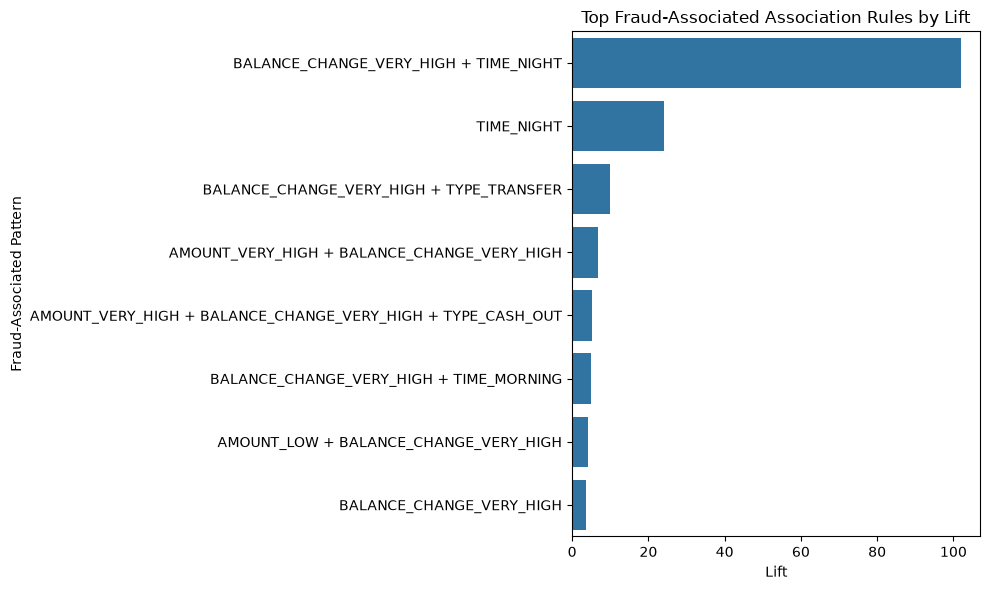

In [45]:
# ============================================================
# 24. VISUALIZE TOP FRAUD RULES
# ============================================================

# Select the top 8 rules based on lift
top_rules = final_fraud_rules.head(8).copy()

# Create a shorter label for the chart
top_rules["rule_label"] = top_rules["rule"].str.replace(
    " → FRAUD", "", regex=False
)

# Plot lift values
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_rules,
    x="lift",
    y="rule_label"
)

plt.xlabel("Lift")
plt.ylabel("Fraud-Associated Pattern")
plt.title("Top Fraud-Associated Association Rules by Lift")
plt.tight_layout()

plt.show()

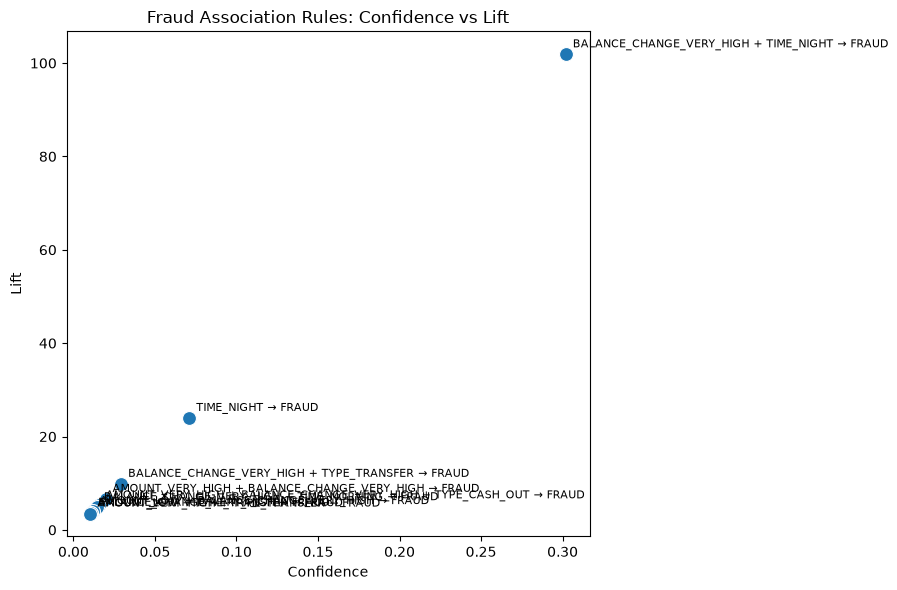

In [46]:
# ============================================================
# 25. CONFIDENCE VS LIFT
# ============================================================

plt.figure(figsize=(9, 6))

# Plot each fraud rule as a point
sns.scatterplot(
    data=final_fraud_rules,
    x="confidence",
    y="lift",
    s=100
)

# Add rule labels to each point
for _, row in final_fraud_rules.iterrows():
    plt.annotate(
        row["rule"],
        (row["confidence"], row["lift"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Confidence")
plt.ylabel("Lift")
plt.title("Fraud Association Rules: Confidence vs Lift")
plt.tight_layout()

plt.show()

In [47]:
# ============================================================
# 26. FRAUD RATE BY TIME CATEGORY
# ============================================================

# Calculate the percentage of fraudulent transactions
# within each time category
fraud_rate_by_time = (
    arm_df.groupby("time_category")["isFraud"]
    .mean() * 100
)

# Sort from highest to lowest fraud rate
fraud_rate_by_time = fraud_rate_by_time.sort_values(
    ascending=False
)

print("Fraud rate by time category:")
print(fraud_rate_by_time)

Fraud rate by time category:
time_category
TIME_NIGHT        7.112061
TIME_MORNING      0.403437
TIME_EVENING      0.204676
TIME_AFTERNOON    0.169734
Name: isFraud, dtype: float64


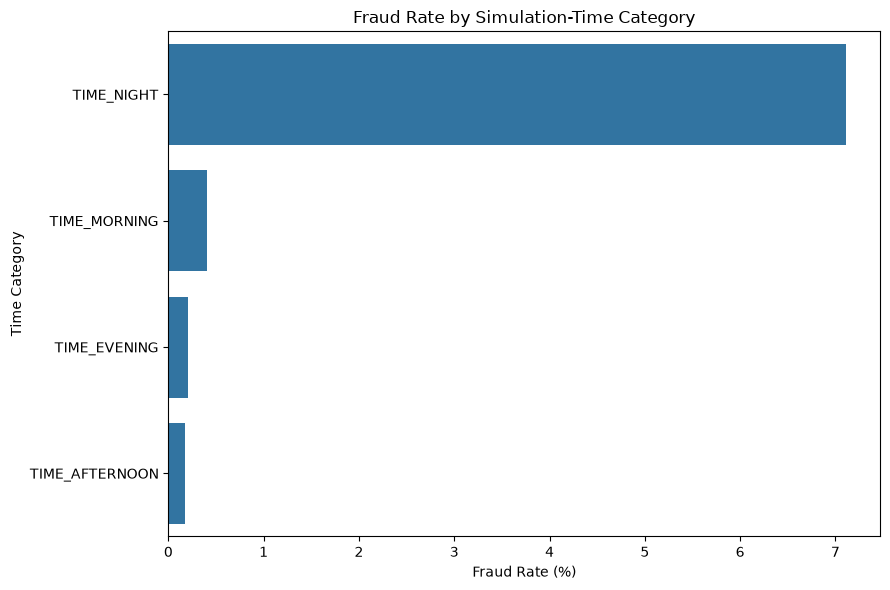

In [48]:
# Plot fraud rate for each time category
plt.figure(figsize=(9, 6))

sns.barplot(
    x=fraud_rate_by_time.values,
    y=fraud_rate_by_time.index
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Time Category")
plt.title("Fraud Rate by Simulation-Time Category")
plt.tight_layout()

plt.show()

In [49]:
# ============================================================
# 27. SAVE FP-GROWTH RESULTS
# ============================================================

# Save all frequent itemsets discovered by FP-Growth
frequent_itemsets.to_csv(
    "../outputs/frequent_itemsets.csv",
    index=False
)

# Save the final fraud-associated rules
final_fraud_rules[
    ["rule", "support", "confidence", "lift"]
].to_csv(
    "../outputs/fraud_rules.csv",
    index=False
)

print("Results saved successfully.")
print("Saved: outputs/frequent_itemsets.csv")
print("Saved: outputs/fraud_rules.csv")

Results saved successfully.
Saved: outputs/frequent_itemsets.csv
Saved: outputs/fraud_rules.csv


In [51]:

from itertools import combinations
import pandas as pd

def count_target_itemsets(transaction_matrix, target_itemsets):
    """
    Count exact support for a specified collection of itemsets.
    transaction_matrix: Boolean DataFrame, one row per transaction.
    target_itemsets: iterable of itemsets, e.g. [("TIME_NIGHT", "FRAUD")].
    """
    results = []
    n_transactions = len(transaction_matrix)

    if n_transactions == 0:
        raise ValueError("transaction_matrix cannot be empty")

    for itemset in target_itemsets:
        items = tuple(itemset)

        missing = set(items) - set(transaction_matrix.columns)
        if missing:
            raise ValueError(f"Missing columns: {sorted(missing)}")

        mask = transaction_matrix[list(items)].all(axis=1)
        count = int(mask.sum())

        results.append({
            "itemsets": items,
            "count": count,
            "support": count / n_transactions
        })

    return pd.DataFrame(results).sort_values(
        "support", ascending=False
    ).reset_index(drop=True)


In [53]:
%whos DataFrame

Variable                Type         Data/Info
----------------------------------------------
arm_df                  DataFrame    Shape: (2770409, 17)
balance_change_stats    DataFrame    Shape: (2, 8)
df                      DataFrame    Shape: (6362620, 11)
final_fraud_rules       DataFrame    Shape: (10, 16)
fraud_balance_pattern   DataFrame    Shape: (4, 2)
fraud_itemsets          DataFrame    Shape: (22, 3)
fraud_rules             DataFrame    Shape: (12, 14)
fraud_time_pattern      DataFrame    Shape: (4, 2)
frequent_itemsets       DataFrame    Shape: (670, 3)
rules                   DataFrame    Shape: (6823, 14)
top_rules               DataFrame    Shape: (8, 17)
transaction_df          DataFrame    Shape: (2770409, 16)


In [54]:
print(arm_df.columns.tolist())
display(arm_df.head())
print(arm_df.dtypes)

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'amount_category', 'balance_change', 'amount_balance_difference', 'balance_change_category', 'hour', 'time_category']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_category,balance_change,amount_balance_difference,balance_change_category,hour,time_category
2,1,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0,AMOUNT_LOW,181.0,0.00,BALANCE_CHANGE_MEDIUM,1,TIME_NIGHT
3,1,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0,AMOUNT_LOW,181.0,0.00,BALANCE_CHANGE_MEDIUM,1,TIME_NIGHT
15,1,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0,AMOUNT_HIGH,15325.0,213808.94,BALANCE_CHANGE_HIGH,1,TIME_NIGHT
19,1,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0,AMOUNT_LOW,705.0,214605.30,BALANCE_CHANGE_HIGH,1,TIME_NIGHT
24,1,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0,AMOUNT_MEDIUM,10835.0,300850.89,BALANCE_CHANGE_HIGH,1,TIME_NIGHT


step                           int64
type                             str
amount                       float64
nameOrig                         str
oldbalanceOrg                float64
newbalanceOrig               float64
nameDest                         str
oldbalanceDest               float64
newbalanceDest               float64
isFraud                        int64
isFlaggedFraud                 int64
amount_category                  str
balance_change               float64
amount_balance_difference    float64
balance_change_category          str
hour                           int64
time_category                    str
dtype: object


In [55]:
print("Transaction types:")
print(arm_df["type"].unique())

print("\nAmount categories:")
print(arm_df["amount_category"].unique())

print("\nBalance change categories:")
print(arm_df["balance_change_category"].unique())

print("\nTime categories:")
print(arm_df["time_category"].unique())

print("\nFraud labels:")
print(arm_df["isFraud"].unique())

Transaction types:
<ArrowStringArray>
['TRANSFER', 'CASH_OUT']
Length: 2, dtype: str

Amount categories:
<ArrowStringArray>
['AMOUNT_LOW', 'AMOUNT_HIGH', 'AMOUNT_MEDIUM', 'AMOUNT_VERY_HIGH']
Length: 4, dtype: str

Balance change categories:
<ArrowStringArray>
[   'BALANCE_CHANGE_MEDIUM',      'BALANCE_CHANGE_HIGH',
 'BALANCE_CHANGE_VERY_HIGH',       'BALANCE_CHANGE_LOW']
Length: 4, dtype: str

Time categories:
<ArrowStringArray>
['TIME_NIGHT', 'TIME_MORNING', 'TIME_AFTERNOON', 'TIME_EVENING']
Length: 4, dtype: str

Fraud labels:
[1 0]


In [56]:

import pandas as pd
import numpy as np
from itertools import combinations

# Use the existing project data
feature_cols = [
    "type",
    "amount_category",
    "balance_change_category",
    "time_category"
]

required_cols = feature_cols + ["isFraud"]

experiment_df = arm_df[required_cols].copy()

# Convert categorical features into consistent strings
for col in feature_cols:
    experiment_df[col] = experiment_df[col].astype(str)

experiment_df["isFraud"] = experiment_df["isFraud"].astype(int)

print("Transactions:", len(experiment_df))
print("Fraud transactions:", experiment_df["isFraud"].sum())
print("Fraud rate:", round(experiment_df["isFraud"].mean() * 100, 4), "%")
display(experiment_df.head())


Transactions: 2770409
Fraud transactions: 8213
Fraud rate: 0.2965 %


,type,amount_category,balance_change_category,time_category,isFraud
2,TRANSFER,AMOUNT_LOW,BALANCE_CHANGE_MEDIUM,TIME_NIGHT,1
3,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_MEDIUM,TIME_NIGHT,1
15,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_HIGH,TIME_NIGHT,0
19,TRANSFER,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_NIGHT,0
24,TRANSFER,AMOUNT_MEDIUM,BALANCE_CHANGE_HIGH,TIME_NIGHT,0


In [57]:

# Deterministic train/test split
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    experiment_df,
    test_size=0.20,
    random_state=42,
    stratify=experiment_df["isFraud"]
)

# Mine patterns from TRAINING data only
n_train = len(train_df)
fraud_rate = train_df["isFraud"].mean()

if fraud_rate == 0:
    raise ValueError("No fraud transactions found in training data.")

feature_values = {
    col: train_df[col].unique().tolist()
    for col in feature_cols
}

# Candidate patterns contain values from distinct features.
# Keep this search limited to 2- and 3-feature combinations.
candidate_rules = []

for size in (2, 3):
    for cols in combinations(feature_cols, size):
        grouped = (
            train_df.groupby(list(cols), observed=True)["isFraud"]
            .agg(["size", "sum"])
            .reset_index()
        )

        # Focus on combinations with at least 5 fraud examples.
        grouped = grouped[grouped["sum"] >= 5]

        for _, row in grouped.iterrows():
            count = int(row["size"])
            fraud_count = int(row["sum"])
            confidence = fraud_count / count
            support = fraud_count / n_train
            lift = confidence / fraud_rate

            # Require association with fraud above the base rate.
            if lift > 1:
                antecedent = tuple(
                    (col, str(row[col])) for col in cols
                )

                candidate_rules.append({
                    "antecedent": antecedent,
                    "pattern": " AND ".join(
                        f"{col}={value}" for col, value in antecedent
                    ),
                    "transaction_count": count,
                    "fraud_count": fraud_count,
                    "support": support,
                    "confidence": confidence,
                    "lift": lift
                })

fraud_focused_rules = pd.DataFrame(candidate_rules)

if fraud_focused_rules.empty:
    print("No rules met the selection criteria.")
else:
    fraud_focused_rules = (
        fraud_focused_rules
        .sort_values(
            ["lift", "fraud_count", "confidence"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("Fraud-focused candidate rules:", len(fraud_focused_rules))
    display(fraud_focused_rules.head(20))


Fraud-focused candidate rules: 88


,antecedent,pattern,transaction_count,fraud_count,support,confidence,lift
0,"((amount_category, AMOUNT_VERY_HIGH), (balance...",amount_category=AMOUNT_VERY_HIGH AND balance_c...,1465,798,0.000360,0.544710,183.752702
1,"((type, TRANSFER), (balance_change_category, B...",type=TRANSFER AND balance_change_category=BALA...,2071,730,0.000329,0.352487,118.908042
2,"((balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,4865,1471,0.000664,0.302364,101.999559
3,"((type, CASH_OUT), (balance_change_category, B...",type=CASH_OUT AND balance_change_category=BALA...,2794,741,0.000334,0.265211,89.466464
4,"((amount_category, AMOUNT_HIGH), (balance_chan...",amount_category=AMOUNT_HIGH AND balance_change...,946,201,0.000091,0.212474,71.675939
5,"((amount_category, AMOUNT_LOW), (balance_chang...",amount_category=AMOUNT_LOW AND balance_change_...,1254,264,0.000119,0.210526,71.019050
6,"((amount_category, AMOUNT_MEDIUM), (balance_ch...",amount_category=AMOUNT_MEDIUM AND balance_chan...,1200,208,0.000094,0.173333,58.472351
7,"((type, TRANSFER), (amount_category, AMOUNT_VE...",type=TRANSFER AND amount_category=AMOUNT_VERY_...,1590,270,0.000122,0.169811,57.284234
8,"((amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH AND time_cate...,5636,801,0.000361,0.142122,47.943529
9,"((type, CASH_OUT), (amount_category, AMOUNT_VE...",type=CASH_OUT AND amount_category=AMOUNT_VERY_...,4046,531,0.000240,0.131241,44.272812


In [59]:

# Optimized scoring: group rows by categorical feature combinations
# and score each unique combination only once.

from itertools import combinations
import numpy as np
import pandas as pd

def score_unique_patterns(test_df, rules, feature_cols):
    result = test_df.copy()

    if rules.empty:
        result["risk_score"] = 0.0
        result["matched_rules"] = ""
        result["matched_rule_count"] = 0
        return result

    # Each row receives a compact signature for its feature values.
    signatures = list(zip(*(result[c].astype(str) for c in feature_cols)))
    unique_signatures = pd.Series(signatures, index=result.index)
    unique_values = unique_signatures.unique()

    score_lookup = {}

    for signature in unique_values:
        row_values = dict(zip(feature_cols, signature))
        matched = []

        for _, rule in rules.iterrows():
            if all(row_values[col] == value
                   for col, value in rule["antecedent"]):
                matched.append(rule)

        by_size = {}
        for rule in matched:
            size = len(rule["antecedent"])
            evidence = (
                max(0.0, np.log(max(float(rule["lift"]), 1.0)))
                * float(rule["confidence"])
            )
            evidence = min(evidence, 3.0)
            by_size[size] = max(by_size.get(size, 0.0), evidence)

        total = sum(by_size.values())
        score = 100 * (1 - np.exp(-total))

        score_lookup[signature] = (
            round(float(score), 2),
            " | ".join(r["pattern"] for r in matched[:5]),
            len(matched)
        )

    mapped = [score_lookup[s] for s in signatures]
    result["risk_score"] = [x[0] for x in mapped]
    result["matched_rules"] = [x[1] for x in mapped]
    result["matched_rule_count"] = [x[2] for x in mapped]

    result["risk_level"] = pd.cut(
        result["risk_score"],
        bins=[-0.01, 25, 60, 100],
        labels=["Low", "Medium", "High"]
    )

    return result


test_scored = score_unique_patterns(
    test_df, fraud_focused_rules, feature_cols
)

display(test_scored.head(20))



,type,amount_category,balance_change_category,time_category,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
5582560,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_MORNING,0,0.00,,0,Low
234002,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_AFTERNOON,0,0.00,,0,Low
1385427,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_EVENING,0,0.00,,0,Low
5655160,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.00,,0,Low
2068910,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.00,,0,Low
1633395,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_HIGH,TIME_AFTERNOON,0,0.20,type=CASH_OUT AND amount_category=AMOUNT_VERY_...,2,Low
292478,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.00,,0,Low
4130289,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_AFTERNOON,0,6.17,amount_category=AMOUNT_VERY_HIGH AND balance_c...,8,Low
2273646,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_EVENING,0,0.00,,0,Low
1241079,CASH_OUT,AMOUNT_MEDIUM,BALANCE_CHANGE_HIGH,TIME_AFTERNOON,0,0.00,,0,Low


In [60]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

threshold = 25

y_true = test_scored["isFraud"]
y_pred = (test_scored["risk_score"] >= threshold).astype(int)

print("Threshold:", threshold)
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("Average Precision:", round(average_precision_score(y_true, test_scored["risk_score"]), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Threshold: 25
Precision: 0.1075
Recall: 0.2386
F1-score: 0.1482
Average Precision: 0.1274
Confusion Matrix:
[[549185   3254]
 [  1251    392]]


In [61]:
high_risk = test_scored[
    test_scored["risk_level"] == "High"
].sort_values("risk_score", ascending=False)

display(high_risk.head(20))
print("Total high-risk transactions:", len(high_risk))

,type,amount_category,balance_change_category,time_category,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
6168656,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
6065199,TRANSFER,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
5563724,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
2375977,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
3955986,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
4783734,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
3606279,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
6117347,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
2799145,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
5560497,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High


Total high-risk transactions: 2267


In [62]:
high_risk = test_scored[
    test_scored["risk_level"] == "High"
].sort_values("risk_score", ascending=False)

display(high_risk.head(20))
print("Total high-risk transactions:", len(high_risk))

,type,amount_category,balance_change_category,time_category,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
6168656,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
6065199,TRANSFER,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
5563724,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
2375977,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
3955986,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
4783734,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
3606279,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
6117347,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,1,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
2799145,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High
5560497,CASH_OUT,AMOUNT_VERY_HIGH,BALANCE_CHANGE_VERY_HIGH,TIME_NIGHT,0,98.56,amount_category=AMOUNT_VERY_HIGH AND balance_c...,10,High


Total high-risk transactions: 2267


In [63]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

fraud_focused_rules.to_csv(
    output_dir / "fraud_focused_rules.csv", index=False
)

test_scored.to_csv(
    output_dir / "fraud_risk_scores.csv", index=False
)

high_risk.to_csv(
    output_dir / "high_risk_transactions.csv", index=False
)

print("All three output files saved in the outputs folder.")

All three output files saved in the outputs folder.


In [64]:
print("========== FRAUD DETECTION SUMMARY ==========")
print("Transactions evaluated:", len(test_scored))
print("Actual fraud transactions:", int(test_scored["isFraud"].sum()))
print("High-risk transactions:", len(high_risk))
print("Fraud-focused rules discovered:", len(fraud_focused_rules))
print("Average risk score:", round(test_scored["risk_score"].mean(), 2))

print("\nRisk level distribution:")
print(test_scored["risk_level"].value_counts(dropna=False))

print("\nTop 10 fraud-focused rules:")
display(fraud_focused_rules.head(10))

========== FRAUD DETECTION SUMMARY ==========
Transactions evaluated: 554082
Actual fraud transactions: 1643
High-risk transactions: 2267
Fraud-focused rules discovered: 88
Average risk score: 2.03

Risk level distribution:
risk_level
Low       550436
High        2267
Medium      1379
Name: count, dtype: int64

Top 10 fraud-focused rules:


,antecedent,pattern,transaction_count,fraud_count,support,confidence,lift
0,"((amount_category, AMOUNT_VERY_HIGH), (balance...",amount_category=AMOUNT_VERY_HIGH AND balance_c...,1465,798,0.000360,0.544710,183.752702
1,"((type, TRANSFER), (balance_change_category, B...",type=TRANSFER AND balance_change_category=BALA...,2071,730,0.000329,0.352487,118.908042
2,"((balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,4865,1471,0.000664,0.302364,101.999559
3,"((type, CASH_OUT), (balance_change_category, B...",type=CASH_OUT AND balance_change_category=BALA...,2794,741,0.000334,0.265211,89.466464
4,"((amount_category, AMOUNT_HIGH), (balance_chan...",amount_category=AMOUNT_HIGH AND balance_change...,946,201,0.000091,0.212474,71.675939
5,"((amount_category, AMOUNT_LOW), (balance_chang...",amount_category=AMOUNT_LOW AND balance_change_...,1254,264,0.000119,0.210526,71.019050
6,"((amount_category, AMOUNT_MEDIUM), (balance_ch...",amount_category=AMOUNT_MEDIUM AND balance_chan...,1200,208,0.000094,0.173333,58.472351
7,"((type, TRANSFER), (amount_category, AMOUNT_VE...",type=TRANSFER AND amount_category=AMOUNT_VERY_...,1590,270,0.000122,0.169811,57.284234
8,"((amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH AND time_cate...,5636,801,0.000361,0.142122,47.943529
9,"((type, CASH_OUT), (amount_category, AMOUNT_VE...",type=CASH_OUT AND amount_category=AMOUNT_VERY_...,4046,531,0.000240,0.131241,44.272812


In [65]:
from pathlib import Path

# Locate the project outputs folder.
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Verify that the risk-scoring results exist.
print("test_scored exists:", "test_scored" in globals())

if "test_scored" not in globals():
    print("Run the risk-scoring Step 4 first.")
else:
    required = {"risk_score", "isFraud"}
    missing = required - set(test_scored.columns)

    if missing:
        print("Missing columns:", missing)
    else:
        test_scored.to_csv(
            output_dir / "fraud_risk_scores.csv",
            index=False
        )

        test_scored[
            test_scored["risk_level"].astype(str) == "High"
        ].to_csv(
            output_dir / "high_risk_transactions.csv",
            index=False
        )

        print("Saved:", (output_dir / "fraud_risk_scores.csv").resolve())
        print("Risk-score columns:", test_scored.columns.tolist())

test_scored exists: True
Saved: D:\projects\machineLearning\notebooks\outputs\fraud_risk_scores.csv
Risk-score columns: ['type', 'amount_category', 'balance_change_category', 'time_category', 'isFraud', 'risk_score', 'matched_rules', 'matched_rule_count', 'risk_level']


In [66]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

test_scored.to_csv(
    output_dir / "fraud_risk_scores.csv",
    index=False
)

test_scored[
    test_scored["risk_level"].astype(str) == "High"
].to_csv(
    output_dir / "high_risk_transactions.csv",
    index=False
)

print("Risk-score files saved to:", output_dir.resolve())

Risk-score files saved to: D:\projects\machineLearning\notebooks\outputs


In [68]:
from pathlib import Path

output_dir = Path(r"D:\projects\machineLearning\outputs")
output_dir.mkdir(parents=True, exist_ok=True)

test_scored.to_csv(
    output_dir / "fraud_risk_scores.csv",
    index=False
)

test_scored[
    test_scored["risk_level"].astype(str) == "High"
].to_csv(
    output_dir / "high_risk_transactions.csv",
    index=False
)

print("Risk scores saved successfully!")
print("Rows:", len(test_scored))
print("File:", output_dir / "fraud_risk_scores.csv")

Risk scores saved successfully!
Rows: 554082
File: D:\projects\machineLearning\outputs\fraud_risk_scores.csv


In [69]:

import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

# Use only the training data for pattern discovery.
# feature_cols should contain:
# type, amount_category, balance_change_category, time_category

MIN_FRAUD_SUPPORT = 0.005
MIN_FRAUD_COUNT = 5
MAX_PATTERN_LENGTH = 3

# Prepare fraud-only transactions
train_work = train_df[feature_cols + ["isFraud"]].copy()

for col in feature_cols:
    train_work[col] = train_work[col].astype(str)

train_work["isFraud"] = train_work["isFraud"].astype(int)

fraud_train = train_work[train_work["isFraud"] == 1].copy()

if fraud_train.empty:
    raise ValueError("No fraudulent transactions found in training data.")

# Convert each feature value into an item, e.g. TYPE=TRANSFER
fraud_transactions = [
    [f"{col}={row[col]}" for col in feature_cols]
    for _, row in fraud_train[feature_cols].iterrows()
]

# One-hot encode the fraud-only transactions
encoder = TransactionEncoder()
encoded_array = encoder.fit(fraud_transactions).transform(
    fraud_transactions
)

fraud_encoded = pd.DataFrame(
    encoded_array,
    columns=encoder.columns_,
    dtype=bool
)

# Mine frequent patterns with FP-Growth
fraud_itemsets = fpgrowth(
    fraud_encoded,
    min_support=MIN_FRAUD_SUPPORT,
    use_colnames=True,
    max_len=MAX_PATTERN_LENGTH
)

# Keep combinations of at least 2 features
fraud_itemsets = fraud_itemsets[
    fraud_itemsets["itemsets"].apply(
        lambda items: len(items) >= 2
    )
].copy()

# Evaluate candidate patterns against the FULL training dataset
n_train = len(train_work)
train_fraud_rate = train_work["isFraud"].mean()

rule_records = []

for _, itemset_row in fraud_itemsets.iterrows():
    items = sorted(itemset_row["itemsets"])

    antecedent = []
    for item in items:
        col, value = item.split("=", 1)
        antecedent.append((col, value))

    # Find transactions matching every item in the pattern
    mask = pd.Series(True, index=train_work.index)

    for col, value in antecedent:
        mask &= train_work[col].eq(value)

    matched_count = int(mask.sum())
    fraud_count = int(
        train_work.loc[mask, "isFraud"].sum()
    )

    if matched_count == 0 or fraud_count < MIN_FRAUD_COUNT:
        continue

    # Metrics calculated on the full training set
    support = fraud_count / n_train
    confidence = fraud_count / matched_count
    lift = (
        confidence / train_fraud_rate
        if train_fraud_rate > 0 else 0.0
    )

    if lift <= 1:
        continue

    pattern_text = " + ".join(
        f"{col}={value}" for col, value in antecedent
    )

    rule_records.append({
        "antecedent": antecedent,
        "pattern": f"{pattern_text} → FRAUD",
        "support": support,
        "confidence": confidence,
        "lift": lift,
        "fraud_count": fraud_count,
        "matched_count": matched_count,
        "pattern_length": len(antecedent)
    })

fraud_focused_rules = pd.DataFrame(rule_records)

if not fraud_focused_rules.empty:
    fraud_focused_rules = (
        fraud_focused_rules
        .sort_values(
            ["lift", "confidence", "fraud_count"],
            ascending=False
        )
        .reset_index(drop=True)
    )

print("Fraud transactions used for mining:", len(fraud_train))
print("Frequent FP-Growth itemsets:", len(fraud_itemsets))
print("Fraud-associated patterns retained:", len(fraud_focused_rules))

display(fraud_focused_rules.head(20))


Fraud transactions used for mining: 6570
Frequent FP-Growth itemsets: 128
Fraud-associated patterns retained: 85


,antecedent,pattern,support,confidence,lift,fraud_count,matched_count,pattern_length
0,"[(amount_category, AMOUNT_VERY_HIGH), (balance...",amount_category=AMOUNT_VERY_HIGH + balance_cha...,0.000360,0.544710,183.752702,798,1465,3
1,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000329,0.352487,118.908042,730,2071,3
2,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000664,0.302364,101.999559,1471,4865,2
3,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000334,0.265211,89.466464,741,2794,3
4,"[(amount_category, AMOUNT_HIGH), (balance_chan...",amount_category=AMOUNT_HIGH + balance_change_c...,0.000091,0.212474,71.675939,201,946,3
5,"[(amount_category, AMOUNT_LOW), (balance_chang...",amount_category=AMOUNT_LOW + balance_change_ca...,0.000119,0.210526,71.019050,264,1254,3
6,"[(amount_category, AMOUNT_MEDIUM), (balance_ch...",amount_category=AMOUNT_MEDIUM + balance_change...,0.000094,0.173333,58.472351,208,1200,3
7,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000122,0.169811,57.284234,270,1590,3
8,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000361,0.142122,47.943529,801,5636,2
9,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000240,0.131241,44.272812,531,4046,3


In [70]:

from pathlib import Path

output_dir = Path(r"D:\projects\machineLearning\outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save a readable version of the rules
rules_to_save = fraud_focused_rules.copy()

if not rules_to_save.empty:
    rules_to_save["antecedent"] = rules_to_save["antecedent"].apply(
        lambda items: str(items)
    )

rules_to_save.to_csv(
    output_dir / "fraud_focused_rules.csv",
    index=False
)

print("Saved:", output_dir / "fraud_focused_rules.csv")


Saved: D:\projects\machineLearning\outputs\fraud_focused_rules.csv


In [71]:

test_scored = score_unique_patterns(
    test_df,
    fraud_focused_rules,
    feature_cols
)

display(
    test_scored[
        ["isFraud", "risk_score", "matched_rules",
         "matched_rule_count", "risk_level"]
    ].head(10)
)


,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
5582560,0,0.00,,0,Low
234002,0,0.00,,0,Low
1385427,0,0.00,,0,Low
5655160,0,0.00,,0,Low
2068910,0,0.00,,0,Low
1633395,0,0.20,amount_category=AMOUNT_VERY_HIGH + type=CASH_O...,2,Low
292478,0,0.00,,0,Low
4130289,0,6.17,amount_category=AMOUNT_VERY_HIGH + balance_cha...,8,Low
2273646,0,0.00,,0,Low
1241079,0,0.00,,0,Low


In [72]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

MIN_FRAUD_SUPPORT = 0.002
MIN_FRAUD_COUNT = 5
MAX_PATTERN_LENGTH = 3

# Use the feature columns already defined in your notebook.
train_work = train_df[feature_cols + ["isFraud"]].copy()

for col in feature_cols:
    train_work[col] = train_work[col].astype(str)

train_work["isFraud"] = train_work["isFraud"].astype(int)

# Mine patterns from fraud cases in the training set only.
fraud_train = train_work[train_work["isFraud"] == 1]

fraud_transactions = [
    [f"{col}={row[col]}" for col in feature_cols]
    for _, row in fraud_train[feature_cols].iterrows()
]

encoder = TransactionEncoder()
encoded_array = encoder.fit(fraud_transactions).transform(
    fraud_transactions
)
fraud_encoded = pd.DataFrame(
    encoded_array,
    columns=encoder.columns_,
    dtype=bool
)

fraud_itemsets = fpgrowth(
    fraud_encoded,
    min_support=MIN_FRAUD_SUPPORT,
    use_colnames=True,
    max_len=MAX_PATTERN_LENGTH
)

# Retain patterns containing at least two items.
fraud_itemsets = fraud_itemsets[
    fraud_itemsets["itemsets"].apply(lambda x: len(x) >= 2)
].copy()

n_train = len(train_work)
train_fraud_rate = train_work["isFraud"].mean()
rule_records = []

for _, itemset_row in fraud_itemsets.iterrows():
    items = sorted(itemset_row["itemsets"])
    antecedent = [
        tuple(item.split("=", 1))
        for item in items
    ]

    mask = pd.Series(True, index=train_work.index)

    for col, value in antecedent:
        mask &= train_work[col].eq(value)

    matched_count = int(mask.sum())
    fraud_count = int(train_work.loc[mask, "isFraud"].sum())

    if matched_count == 0 or fraud_count < MIN_FRAUD_COUNT:
        continue

    support = fraud_count / n_train
    confidence = fraud_count / matched_count
    lift = (
        confidence / train_fraud_rate
        if train_fraud_rate > 0 else 0.0
    )

    pattern_text = " + ".join(
        f"{col}={value}" for col, value in antecedent
    )

    rule_records.append({
        "antecedent": antecedent,
        "pattern": f"{pattern_text} → FRAUD",
        "support": support,
        "confidence": confidence,
        "lift": lift,
        "fraud_count": fraud_count,
        "matched_count": matched_count,
        "pattern_length": len(antecedent)
    })

fraud_focused_rules = pd.DataFrame(rule_records)

if not fraud_focused_rules.empty:
    fraud_focused_rules = fraud_focused_rules.sort_values(
        ["lift", "confidence", "fraud_count"],
        ascending=False
    ).reset_index(drop=True)

print("Fraud training transactions:", len(fraud_train))
print("Frequent fraud itemsets:", len(fraud_itemsets))
print("Fraud-focused patterns:", len(fraud_focused_rules))

display(fraud_focused_rules.head(20))

Fraud training transactions: 6570
Frequent fraud itemsets: 136
Fraud-focused patterns: 136


,antecedent,pattern,support,confidence,lift,fraud_count,matched_count,pattern_length
0,"[(amount_category, AMOUNT_VERY_HIGH), (balance...",amount_category=AMOUNT_VERY_HIGH + balance_cha...,0.000360,0.544710,183.752702,798,1465,3
1,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000329,0.352487,118.908042,730,2071,3
2,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000664,0.302364,101.999559,1471,4865,2
3,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000334,0.265211,89.466464,741,2794,3
4,"[(amount_category, AMOUNT_HIGH), (balance_chan...",amount_category=AMOUNT_HIGH + balance_change_c...,0.000091,0.212474,71.675939,201,946,3
5,"[(amount_category, AMOUNT_LOW), (balance_chang...",amount_category=AMOUNT_LOW + balance_change_ca...,0.000119,0.210526,71.019050,264,1254,3
6,"[(amount_category, AMOUNT_MEDIUM), (balance_ch...",amount_category=AMOUNT_MEDIUM + balance_change...,0.000094,0.173333,58.472351,208,1200,3
7,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000122,0.169811,57.284234,270,1590,3
8,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000361,0.142122,47.943529,801,5636,2
9,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000240,0.131241,44.272812,531,4046,3


In [73]:
from pathlib import Path

output_dir = Path(r"D:\projects\machineLearning\outputs")
output_dir.mkdir(parents=True, exist_ok=True)

rules_to_save = fraud_focused_rules.copy()

# Store antecedents in a readable format in the CSV.
if not rules_to_save.empty:
    rules_to_save["antecedent"] = rules_to_save["antecedent"].apply(
        lambda items: str(items)
    )

rules_to_save.to_csv(
    output_dir / "fraud_focused_rules.csv",
    index=False
)

print("Saved fraud-focused patterns.")

Saved fraud-focused patterns.


In [74]:
test_scored = score_unique_patterns(
    test_df,
    fraud_focused_rules,
    feature_cols
)

print(test_scored["risk_level"].value_counts(dropna=False))
display(test_scored.head())

risk_level
Low       550436
High        2267
Medium      1379
Name: count, dtype: int64


,type,amount_category,balance_change_category,time_category,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
5582560,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_MORNING,0,0.0,time_category=TIME_MORNING + type=CASH_OUT → F...,5,Low
234002,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_AFTERNOON,0,0.0,amount_category=AMOUNT_LOW + balance_change_ca...,10,Low
1385427,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_EVENING,0,0.0,amount_category=AMOUNT_LOW + balance_change_ca...,10,Low
5655160,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.0,time_category=TIME_AFTERNOON + type=CASH_OUT →...,7,Low
2068910,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.0,amount_category=AMOUNT_LOW + time_category=TIM...,9,Low


In [75]:
test_scored = score_unique_patterns(
    test_df,
    fraud_focused_rules,
    feature_cols
)

print(test_scored["risk_level"].value_counts(dropna=False))
display(test_scored.head())

risk_level
Low       550436
High        2267
Medium      1379
Name: count, dtype: int64


,type,amount_category,balance_change_category,time_category,isFraud,risk_score,matched_rules,matched_rule_count,risk_level
5582560,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_MORNING,0,0.0,time_category=TIME_MORNING + type=CASH_OUT → F...,5,Low
234002,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_AFTERNOON,0,0.0,amount_category=AMOUNT_LOW + balance_change_ca...,10,Low
1385427,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_HIGH,TIME_EVENING,0,0.0,amount_category=AMOUNT_LOW + balance_change_ca...,10,Low
5655160,CASH_OUT,AMOUNT_HIGH,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.0,time_category=TIME_AFTERNOON + type=CASH_OUT →...,7,Low
2068910,CASH_OUT,AMOUNT_LOW,BALANCE_CHANGE_LOW,TIME_AFTERNOON,0,0.0,amount_category=AMOUNT_LOW + time_category=TIM...,9,Low


In [76]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

threshold = 25

y_true = test_scored["isFraud"].astype(int)
y_score = test_scored["risk_score"].astype(float)
y_pred = (y_score >= threshold).astype(int)

print("Threshold:", threshold)
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))
print("Average precision:", average_precision_score(y_true, y_score))
print("\nConfusion matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification report:\n",
      classification_report(y_true, y_pred, zero_division=0))

Threshold: 25
Precision: 0.10751508502468458
Recall: 0.23858794887401097
F1-score: 0.14823217999621857
Average precision: 0.12737256690230947

Confusion matrix:
 [[549185   3254]
 [  1251    392]]

Classification report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00    552439
           1       0.11      0.24      0.15      1643

    accuracy                           0.99    554082
   macro avg       0.55      0.62      0.57    554082
weighted avg       1.00      0.99      0.99    554082



In [77]:
test_scored.to_csv(
    output_dir / "fraud_risk_scores.csv",
    index=False
)

high_risk = test_scored[
    test_scored["risk_level"].astype(str) == "High"
].copy()

high_risk.to_csv(
    output_dir / "high_risk_transactions.csv",
    index=False
)

print("Saved fraud_risk_scores.csv")
print("Saved high_risk_transactions.csv")
print("High-risk transactions:", len(high_risk))

Saved fraud_risk_scores.csv
Saved high_risk_transactions.csv
High-risk transactions: 2267


In [79]:

import pandas as pd
from sklearn.model_selection import train_test_split

feature_cols = [
    "type",
    "amount_category",
    "balance_change_category",
    "time_category"
]

# Keep only the columns needed for this experiment
experiment_df = arm_df[feature_cols + ["isFraud"]].dropna().copy()

for col in feature_cols:
    experiment_df[col] = experiment_df[col].astype(str)

experiment_df["isFraud"] = experiment_df["isFraud"].astype(int)

# Split before mining to avoid using test data to discover patterns
fg_train, fg_test = train_test_split(
    experiment_df,
    test_size=0.20,
    random_state=42,
    stratify=experiment_df["isFraud"]
)

print("Training transactions:", len(fg_train))
print("Testing transactions:", len(fg_test))
print("Fraud cases in training:", int(fg_train["isFraud"].sum()))
print("Fraud cases in testing:", int(fg_test["isFraud"].sum()))


Training transactions: 2216327
Testing transactions: 554082
Fraud cases in training: 6570
Fraud cases in testing: 1643


In [81]:

%pip install mlxtend


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [82]:

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from itertools import combinations

# Settings you can tune later
MIN_FRAUD_SUPPORT = 0.005
MIN_FRAUD_COUNT = 5
MAX_PATTERN_LENGTH = 3

# Discover candidates using FRAUD CASES ONLY
fraud_train = fg_train[fg_train["isFraud"] == 1]

fraud_transactions = [
    [f"{col}={row[col]}" for col in feature_cols]
    for _, row in fraud_train[feature_cols].iterrows()
]

encoder = TransactionEncoder()
encoded = encoder.fit(fraud_transactions).transform(
    fraud_transactions
)

fraud_encoded = pd.DataFrame(
    encoded,
    columns=encoder.columns_,
    dtype=bool
)

candidate_itemsets = fpgrowth(
    fraud_encoded,
    min_support=MIN_FRAUD_SUPPORT,
    use_colnames=True,
    max_len=MAX_PATTERN_LENGTH
)

# Keep patterns containing at least two different features
candidate_itemsets = candidate_itemsets[
    candidate_itemsets["itemsets"].apply(
        lambda items: len(items) >= 2
    )
].copy()

print("Fraud training cases:", len(fraud_train))
print("Candidate patterns discovered:", len(candidate_itemsets))
display(candidate_itemsets.head(10))


Fraud training cases: 6570
Candidate patterns discovered: 128


,support,itemsets
13,0.460578,"frozenset({type=CASH_OUT, balance_change_categ..."
14,0.223896,frozenset({balance_change_category=BALANCE_CHA...
15,0.122679,"frozenset({type=CASH_OUT, time_category=TIME_N..."
16,0.059665,"frozenset({amount_category=AMOUNT_LOW, time_ca..."
17,0.121309,"frozenset({type=TRANSFER, time_category=TIME_N..."
18,0.121918,"frozenset({amount_category=AMOUNT_VERY_HIGH, t..."
19,0.112785,"frozenset({type=CASH_OUT, balance_change_categ..."
20,0.040183,"frozenset({amount_category=AMOUNT_LOW, balance..."
21,0.019330,"frozenset({type=CASH_OUT, amount_category=AMOU..."
22,0.040335,"frozenset({amount_category=AMOUNT_LOW, type=TR..."


In [84]:

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

# Start with a sample to test the baseline quickly
SAMPLE_SIZE = min(100_000, len(fg_train))

baseline_sample = fg_train.sample(
    n=SAMPLE_SIZE,
    random_state=42
)

baseline_transactions = [
    [f"{col}={row[col]}" for col in feature_cols]
    for row in baseline_sample[feature_cols].to_dict("records")
]

baseline_encoder = TransactionEncoder()
baseline_array = baseline_encoder.fit(
    baseline_transactions
).transform(baseline_transactions)

baseline_encoded = pd.DataFrame(
    baseline_array,
    columns=baseline_encoder.columns_,
    dtype=bool
)

baseline_itemsets = fpgrowth(
    baseline_encoded,
    min_support=0.005,
    use_colnames=True,
    max_len=3
)

baseline_itemsets = baseline_itemsets[
    baseline_itemsets["itemsets"].apply(
        lambda items: len(items) >= 2
    )
].copy()

print("Sample size:", SAMPLE_SIZE)
print("Baseline patterns found:", len(baseline_itemsets))
display(baseline_itemsets.head(10))


Sample size: 100000
Baseline patterns found: 170


,support,itemsets
14,0.36962,frozenset({balance_change_category=BALANCE_CHA...
15,0.20190,"frozenset({type=CASH_OUT, amount_category=AMOU..."
16,0.12229,frozenset({balance_change_category=BALANCE_CHA...
17,0.10088,"frozenset({time_category=TIME_EVENING, amount_..."
18,0.10540,"frozenset({time_category=TIME_AFTERNOON, amoun..."
19,0.09533,frozenset({balance_change_category=BALANCE_CHA...
20,0.08097,"frozenset({type=CASH_OUT, time_category=TIME_E..."
21,0.04559,frozenset({balance_change_category=BALANCE_CHA...
22,0.08565,"frozenset({time_category=TIME_AFTERNOON, type=..."
23,0.05397,"frozenset({time_category=TIME_AFTERNOON, balan..."


In [87]:

print("Fraud-guided rules exists:", "fraud_guided_rules" in globals())
print("Candidate itemsets exists:", "candidate_itemsets" in globals())

# Look for similar variable names already in your notebook
print([
    name for name in globals()
    if "fraud" in name.lower() and "rule" in name.lower()
])


Fraud-guided rules exists: False
Candidate itemsets exists: True
['fraud_rules', 'final_fraud_rules', 'fraud_focused_rules']


In [88]:

print("Baseline itemsets:", len(baseline_itemsets))

print("Fraud-guided patterns:", len(fraud_focused_rules))

print("\nTop standard FP-Growth patterns:")
display(
    baseline_itemsets
    .sort_values("support", ascending=False)
    .head(10)
)

print("\nTop fraud-guided patterns:")
display(fraud_focused_rules.head(10))


Baseline itemsets: 170
Fraud-guided patterns: 136

Top standard FP-Growth patterns:


,support,itemsets
14,0.36962,frozenset({balance_change_category=BALANCE_CHA...
60,0.36008,"frozenset({time_category=TIME_AFTERNOON, type=..."
123,0.29384,"frozenset({type=CASH_OUT, time_category=TIME_E..."
107,0.21097,"frozenset({type=CASH_OUT, balance_change_categ..."
59,0.20672,"frozenset({time_category=TIME_AFTERNOON, balan..."
143,0.20533,"frozenset({type=CASH_OUT, balance_change_categ..."
64,0.20345,"frozenset({type=CASH_OUT, amount_category=AMOU..."
162,0.20244,"frozenset({amount_category=AMOUNT_HIGH, type=C..."
126,0.20193,"frozenset({type=CASH_OUT, amount_category=AMOU..."
15,0.20190,"frozenset({type=CASH_OUT, amount_category=AMOU..."



Top fraud-guided patterns:


,antecedent,pattern,support,confidence,lift,fraud_count,matched_count,pattern_length
0,"[(amount_category, AMOUNT_VERY_HIGH), (balance...",amount_category=AMOUNT_VERY_HIGH + balance_cha...,0.000360,0.544710,183.752702,798,1465,3
1,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000329,0.352487,118.908042,730,2071,3
2,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000664,0.302364,101.999559,1471,4865,2
3,"[(balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,0.000334,0.265211,89.466464,741,2794,3
4,"[(amount_category, AMOUNT_HIGH), (balance_chan...",amount_category=AMOUNT_HIGH + balance_change_c...,0.000091,0.212474,71.675939,201,946,3
5,"[(amount_category, AMOUNT_LOW), (balance_chang...",amount_category=AMOUNT_LOW + balance_change_ca...,0.000119,0.210526,71.019050,264,1254,3
6,"[(amount_category, AMOUNT_MEDIUM), (balance_ch...",amount_category=AMOUNT_MEDIUM + balance_change...,0.000094,0.173333,58.472351,208,1200,3
7,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000122,0.169811,57.284234,270,1590,3
8,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000361,0.142122,47.943529,801,5636,2
9,"[(amount_category, AMOUNT_VERY_HIGH), (time_ca...",amount_category=AMOUNT_VERY_HIGH + time_catego...,0.000240,0.131241,44.272812,531,4046,3


In [89]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Match fraud-guided patterns against held-out test transactions
y_true = fg_test["isFraud"].astype(int)
risk_score = pd.Series(0, index=fg_test.index, dtype=int)

for _, rule in fraud_guided_rules.iterrows():
    items = rule["pattern"].split(" + ")
    mask = pd.Series(True, index=fg_test.index)

    for item in items:
        col, value = item.split("=", 1)
        mask &= fg_test[col].astype(str).eq(value)

    # Add one point for each matching fraud-related pattern
    risk_score.loc[mask] += 1

# Flag a transaction if at least one pattern matches
y_pred = (risk_score > 0).astype(int)

print("Fraud-guided method — test results")
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:   ", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score: ", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))


NameError: name 'fraud_guided_rules' is not defined

In [90]:
print("fraud_guided_rules exists:", "fraud_guided_rules" in globals())
print("fraud_focused_rules exists:", "fraud_focused_rules" in globals())

if "fraud_focused_rules" in globals():
    print("Columns:", fraud_focused_rules.columns.tolist())
    print("Number of rules:", len(fraud_focused_rules))

fraud_guided_rules exists: False
fraud_focused_rules exists: True
Columns: ['antecedent', 'pattern', 'support', 'confidence', 'lift', 'fraud_count', 'matched_count', 'pattern_length']
Number of rules: 136


In [91]:

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Actual fraud labels in the test set
y_true = fg_test["isFraud"].astype(int)

# Start every transaction with a risk score of zero
risk_score = pd.Series(0, index=fg_test.index, dtype=int)

# Match existing fraud-focused patterns against test transactions
for _, rule in fraud_focused_rules.iterrows():
    items = rule["pattern"].split(" + ")

    mask = pd.Series(True, index=fg_test.index)

    for item in items:
        col, value = item.split("=", 1)
        mask &= fg_test[col].astype(str).eq(value)

    # Increase risk score for every matching rule
    risk_score.loc[mask] += 1

# Predict fraud if at least one rule matches
y_pred = (risk_score > 0).astype(int)

print("Fraud-focused Rule Evaluation")
print("-----------------------------")
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


Fraud-focused Rule Evaluation
-----------------------------
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[552439      0]
 [  1643      0]]


In [92]:

print("Number of rules:", len(fraud_focused_rules))
print("Test transactions:", len(fg_test))
print("Actual fraud cases:", int(fg_test["isFraud"].sum()))

# Check how many transactions match at least one rule
matched_transactions = 0
matched_fraud_transactions = 0

for _, rule in fraud_focused_rules.iterrows():
    items = rule["pattern"].split(" + ")
    mask = pd.Series(True, index=fg_test.index)

    for item in items:
        col, value = item.split("=", 1)
        mask &= fg_test[col].astype(str).eq(value)

    matched_transactions += int(mask.sum())
    matched_fraud_transactions += int(
        (mask & fg_test["isFraud"].eq(1)).sum()
    )

print("Sum of rule matches (duplicates possible):", matched_transactions)
print("Sum of fraud matches (duplicates possible):", matched_fraud_transactions)

print("\nExample rule patterns:")
print(fraud_focused_rules["pattern"].head(5).to_list())


Number of rules: 136
Test transactions: 554082
Actual fraud cases: 1643
Sum of rule matches (duplicates possible): 0
Sum of fraud matches (duplicates possible): 0

Example rule patterns:
['amount_category=AMOUNT_VERY_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT + type=TRANSFER → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT + type=CASH_OUT → FRAUD', 'amount_category=AMOUNT_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD']


In [94]:

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

y_true = fg_test["isFraud"].astype(int)

risk_score = pd.Series(0, index=fg_test.index, dtype=int)

for _, rule in fraud_focused_rules.iterrows():

    # Remove the rule's prediction label, e.g. "→ FRAUD"
    pattern = rule["pattern"].split("→")[0].strip()

    items = pattern.split(" + ")
    mask = pd.Series(True, index=fg_test.index)

    for item in items:
        col, value = item.split("=", 1)
        mask &= fg_test[col].astype(str).eq(value)

    risk_score.loc[mask] += 1

# Predict fraud when at least one rule matches
y_pred = (risk_score > 0).astype(int)

print("Fraud-focused Rule Evaluation")
print("-----------------------------")
print("Rules:", len(fraud_focused_rules))
print("Transactions matched:", int((risk_score > 0).sum()))
print("Fraud transactions detected:", int(((y_pred == 1) & (y_true == 1)).sum()))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


Fraud-focused Rule Evaluation
-----------------------------
Rules: 136
Transactions matched: 554082
Fraud transactions detected: 1643
Precision: 0.003
Recall: 1.0
F1-score: 0.0059

Confusion Matrix:
[[     0 552439]
 [     0   1643]]


In [96]:

# Check the feature values in the test set
for col in ["type", "amount_category",
            "balance_change_category", "time_category"]:
    print(f"\n{col}:")
    print(fg_test[col].value_counts(dropna=False).head(10))

# Inspect several complete rules
print("\nFirst 10 fraud-focused rules:")
print(fraud_focused_rules[
    ["pattern", "confidence", "lift", "fraud_count", "matched_count"]
].head(10).to_string(index=False))



type:
type
CASH_OUT    447336
TRANSFER    106746
Name: count, dtype: int64

amount_category:
amount_category
AMOUNT_MEDIUM       138693
AMOUNT_LOW          138534
AMOUNT_VERY_HIGH    138458
AMOUNT_HIGH         138397
Name: count, dtype: int64

balance_change_category:
balance_change_category
BALANCE_CHANGE_LOW          261690
BALANCE_CHANGE_VERY_HIGH    138721
BALANCE_CHANGE_HIGH         138113
BALANCE_CHANGE_MEDIUM        15558
Name: count, dtype: int64

time_category:
time_category
TIME_AFTERNOON    244444
TIME_EVENING      199807
TIME_MORNING      104173
TIME_NIGHT          5658
Name: count, dtype: int64

First 10 fraud-focused rules:
                                                                                                               pattern  confidence       lift  fraud_count  matched_count
amount_category=AMOUNT_VERY_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD    0.544710 183.752702          798           1465
             

In [97]:

rule_match_counts = pd.Series(0, index=fg_test.index, dtype=int)

for _, rule in fraud_focused_rules.iterrows():
    pattern = rule["pattern"].split("→")[0].strip()
    items = pattern.split(" + ")

    mask = pd.Series(True, index=fg_test.index)

    for item in items:
        col, value = item.split("=", 1)
        mask &= fg_test[col].astype(str).eq(value)

    rule_match_counts += mask.astype(int)

print("Minimum matching rules:", rule_match_counts.min())
print("Maximum matching rules:", rule_match_counts.max())
print("\nTransactions matching exactly 0 rules:",
      int((rule_match_counts == 0).sum()))
print("Transactions matching exactly 1 rule:",
      int((rule_match_counts == 1).sum()))
print("Transactions matching 2+ rules:",
      int((rule_match_counts >= 2).sum()))


Minimum matching rules: 4
Maximum matching rules: 10

Transactions matching exactly 0 rules: 0
Transactions matching exactly 1 rule: 0
Transactions matching 2+ rules: 554082


In [98]:

from sklearn.metrics import precision_score, recall_score, f1_score

y_true = fg_test["isFraud"].astype(int)

print("Threshold comparison")
print("-" * 75)
print(f"{'Threshold':<12}{'Flagged':<12}{'Precision':<14}{'Recall':<12}{'F1-score':<12}")

for threshold in range(1, 11):
    y_pred_threshold = (rule_match_counts >= threshold).astype(int)

    precision = precision_score(y_true, y_pred_threshold, zero_division=0)
    recall = recall_score(y_true, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_true, y_pred_threshold, zero_division=0)

    print(
        f"{threshold:<12}"
        f"{int(y_pred_threshold.sum()):<12}"
        f"{precision:<14.4f}"
        f"{recall:<12.4f}"
        f"{f1:<12.4f}"
    )


Threshold comparison
---------------------------------------------------------------------------
Threshold   Flagged     Precision     Recall      F1-score    
1           554082      0.0030        1.0000      0.0059      
2           554082      0.0030        1.0000      0.0059      
3           554082      0.0030        1.0000      0.0059      
4           554082      0.0030        1.0000      0.0059      
5           542474      0.0030        1.0000      0.0060      
6           463714      0.0035        0.9945      0.0070      
7           415892      0.0039        0.9939      0.0078      
8           229669      0.0071        0.9921      0.0141      
9           203335      0.0080        0.9915      0.0159      
10          180230      0.0090        0.9909      0.0179      


In [99]:

print("Training rows:", len(fg_train))
print("Test rows:", len(fg_test))

print("\nFraud-focused rule columns:")
print(fraud_focused_rules.columns.tolist())

print("\nRule-generation variables currently available:")
for name in [
    "fraud_train",
    "fraud_transactions",
    "candidate_itemsets",
    "fraud_guided_rules",
    "fraud_focused_rules"
]:
    print(name, "exists:", name in globals())

print("\nTop 10 rules by confidence:")
print(
    fraud_focused_rules[
        ["pattern", "confidence", "lift", "fraud_count", "matched_count"]
    ].sort_values("confidence", ascending=False).head(10).to_string(index=False)
)


Training rows: 2216327
Test rows: 554082

Fraud-focused rule columns:
['antecedent', 'pattern', 'support', 'confidence', 'lift', 'fraud_count', 'matched_count', 'pattern_length']

Rule-generation variables currently available:
fraud_train exists: True
fraud_transactions exists: True
candidate_itemsets exists: True
fraud_guided_rules exists: False
fraud_focused_rules exists: True

Top 10 rules by confidence:
                                                                                                               pattern  confidence       lift  fraud_count  matched_count
amount_category=AMOUNT_VERY_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD    0.544710 183.752702          798           1465
                   balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT + type=TRANSFER → FRAUD    0.352487 118.908042          730           2071
                                   balance_change_category=BALANCE_CHANGE_VERY_

In [100]:

print("First 5 antecedents:")
print(fraud_focused_rules["antecedent"].head().to_list())

print("\nFirst 5 patterns:")
print(fraud_focused_rules["pattern"].head().to_list())

print("\nFraud training rows:", len(fraud_train))
print("Fraud training transactions:", len(fraud_transactions))
print("Candidate itemsets:", len(candidate_itemsets))


First 5 antecedents:
[[('amount_category', 'AMOUNT_VERY_HIGH'), ('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT')], [('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT'), ('type', 'TRANSFER')], [('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT')], [('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT'), ('type', 'CASH_OUT')], [('amount_category', 'AMOUNT_HIGH'), ('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT')]]

First 5 patterns:
['amount_category=AMOUNT_VERY_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT + type=TRANSFER → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD', 'balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category

In [101]:

rule = fraud_focused_rules.iloc[0]

print("Rule pattern:")
print(rule["pattern"])

print("\nAntecedent:")
print(rule["antecedent"])

# Build a mask from the structured antecedent
mask = pd.Series(True, index=fg_test.index)

for col, value in rule["antecedent"]:
    mask &= fg_test[col].astype(str).eq(str(value))

print("\nTransactions matched by first rule:", int(mask.sum()))
print("Fraud transactions matched:", int((mask & fg_test["isFraud"].eq(1)).sum()))
print("Legitimate transactions matched:", int((mask & fg_test["isFraud"].eq(0)).sum()))


Rule pattern:
amount_category=AMOUNT_VERY_HIGH + balance_change_category=BALANCE_CHANGE_VERY_HIGH + time_category=TIME_NIGHT → FRAUD

Antecedent:
[('amount_category', 'AMOUNT_VERY_HIGH'), ('balance_change_category', 'BALANCE_CHANGE_VERY_HIGH'), ('time_category', 'TIME_NIGHT')]

Transactions matched by first rule: 365
Fraud transactions matched: 198
Legitimate transactions matched: 167


In [102]:

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

y_true = fg_test["isFraud"].astype(int)
risk_score = pd.Series(0, index=fg_test.index, dtype=int)

for _, rule in fraud_focused_rules.iterrows():
    mask = pd.Series(True, index=fg_test.index)

    for col, value in rule["antecedent"]:
        mask &= fg_test[col].astype(str).eq(str(value))

    risk_score += mask.astype(int)

print("Risk score distribution:")
print(risk_score.value_counts().sort_index().to_string())

# Use threshold 10 for this diagnostic comparison
threshold = 10
y_pred = (risk_score >= threshold).astype(int)

print("\nEvaluation at threshold", threshold)
print("Transactions flagged:", int(y_pred.sum()))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))


Risk score distribution:
4      11608
5      78760
6      47822
7     186223
8      26334
9      23105
10    180230

Evaluation at threshold 10
Transactions flagged: 180230
Precision: 0.009
Recall: 0.9909
F1-score: 0.0179

Confusion matrix:
[[373837 178602]
 [    15   1628]]


In [103]:

# Weighted risk scoring using training-derived rule lift
weighted_risk = pd.Series(0.0, index=fg_test.index)

for _, rule in fraud_focused_rules.iterrows():
    mask = pd.Series(True, index=fg_test.index)

    for col, value in rule["antecedent"]:
        mask &= fg_test[col].astype(str).eq(str(value))

    # Use log lift so extremely large lift values do not dominate
    weight = np.log1p(max(float(rule["lift"]), 0))
    weighted_risk += mask.astype(float) * weight

print("Weighted risk score distribution:")
print(weighted_risk.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nHighest weighted risk scores:")
print(weighted_risk.nlargest(10).to_list())


Weighted risk score distribution:
count    554082.000000
mean          4.492359
std           4.051302
min           0.931536
50%           3.237884
75%           6.414819
90%          10.979815
95%          12.723777
99%          17.759754
max          34.733182
dtype: float64

Highest weighted risk scores:
[34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277, 34.73318204346277]


In [104]:

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

y_true = fg_test["isFraud"].astype(int)

# Test several score thresholds for diagnostic purposes
thresholds = sorted(set([
    float(weighted_risk.quantile(0.90)),
    float(weighted_risk.quantile(0.95)),
    float(weighted_risk.quantile(0.99)),
    15.0,
    20.0,
    25.0
]))

print(f"{'Threshold':<12}{'Flagged':<12}{'Precision':<14}{'Recall':<12}{'F1-score':<12}")

for threshold in thresholds:
    y_pred_weighted = (weighted_risk >= threshold).astype(int)

    precision = precision_score(y_true, y_pred_weighted, zero_division=0)
    recall = recall_score(y_true, y_pred_weighted, zero_division=0)
    f1 = f1_score(y_true, y_pred_weighted, zero_division=0)

    print(
        f"{threshold:<12.2f}"
        f"{int(y_pred_weighted.sum()):<12}"
        f"{precision:<14.4f}"
        f"{recall:<12.4f}"
        f"{f1:<12.4f}"
    )


Threshold   Flagged     Precision     Recall      F1-score    
10.98       64212       0.0213        0.8314      0.0415      
12.72       34531       0.0334        0.7030      0.0639      
15.00       15133       0.0539        0.4960      0.0972      
17.76       5850        0.1014        0.3609      0.1583      
20.00       1424        0.2633        0.2282      0.2445      
25.00       871         0.3697        0.1960      0.2562      


In [105]:

from sklearn.model_selection import train_test_split

rule_train, rule_val = train_test_split(
    fg_train,
    test_size=0.20,
    random_state=42,
    stratify=fg_train["isFraud"]
)

print("Rule-training rows:", len(rule_train))
print("Validation rows:", len(rule_val))
print("Validation fraud cases:", int(rule_val["isFraud"].sum()))


Rule-training rows: 1773061
Validation rows: 443266
Validation fraud cases: 1314


In [106]:

import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

feature_cols = [
    "type",
    "amount_category",
    "balance_change_category",
    "time_category"
]

MIN_FRAUD_SUPPORT = 0.005
MIN_FRAUD_COUNT = 5
MAX_PATTERN_LENGTH = 3

# Use only fraud cases from rule-training data to discover candidates
fraud_rule_train = rule_train[rule_train["isFraud"] == 1]

fraud_transactions_rule_train = [
    [f"{col}={row[col]}" for col in feature_cols]
    for row in fraud_rule_train[feature_cols].to_dict("records")
]

encoder_rule_train = TransactionEncoder()
encoded_rule_train = encoder_rule_train.fit(
    fraud_transactions_rule_train
).transform(fraud_transactions_rule_train)

fraud_encoded_rule_train = pd.DataFrame(
    encoded_rule_train,
    columns=encoder_rule_train.columns_,
    dtype=bool
)

candidate_itemsets_rule_train = fpgrowth(
    fraud_encoded_rule_train,
    min_support=MIN_FRAUD_SUPPORT,
    use_colnames=True,
    max_len=MAX_PATTERN_LENGTH
)

candidate_itemsets_rule_train = candidate_itemsets_rule_train[
    candidate_itemsets_rule_train["itemsets"].apply(
        lambda items: len(items) >= 2
    )
].copy()

# Evaluate candidate patterns using rule-training data only
overall_fraud_rate_train = rule_train["isFraud"].mean()
rule_records_train = []

for items in candidate_itemsets_rule_train["itemsets"]:
    pattern = list(items)
    mask = pd.Series(True, index=rule_train.index)

    for item in pattern:
        col, value = item.split("=", 1)
        mask &= rule_train[col].astype(str).eq(value)

    matched_count = int(mask.sum())
    fraud_count = int(rule_train.loc[mask, "isFraud"].sum())

    if matched_count == 0 or fraud_count < MIN_FRAUD_COUNT:
        continue

    confidence = fraud_count / matched_count
    lift = (
        confidence / overall_fraud_rate_train
        if overall_fraud_rate_train > 0 else 0
    )

    if lift <= 1:
        continue

    rule_records_train.append({
        "antecedent": [
            tuple(item.split("=", 1)) for item in sorted(pattern)
        ],
        "pattern": " + ".join(sorted(pattern)) + " → FRAUD",
        "support": fraud_count / len(rule_train),
        "confidence": confidence,
        "lift": lift,
        "fraud_count": fraud_count,
        "matched_count": matched_count,
        "pattern_length": len(pattern)
    })

fraud_rules_train = pd.DataFrame(rule_records_train)

if not fraud_rules_train.empty:
    fraud_rules_train = fraud_rules_train.sort_values(
        ["lift", "confidence", "fraud_count"],
        ascending=False
    ).reset_index(drop=True)

print("Fraud cases used to discover candidates:", len(fraud_rule_train))
print("Candidate itemsets:", len(candidate_itemsets_rule_train))
print("Final fraud-focused rules:", len(fraud_rules_train))


Fraud cases used to discover candidates: 5256
Candidate itemsets: 128
Final fraud-focused rules: 85


In [107]:

# Score validation transactions using rules trained on rule_train
weighted_val_risk = pd.Series(0.0, index=rule_val.index)

for _, rule in fraud_rules_train.iterrows():
    mask = pd.Series(True, index=rule_val.index)

    for col, value in rule["antecedent"]:
        mask &= rule_val[col].astype(str).eq(str(value))

    weight = np.log1p(max(float(rule["lift"]), 0))
    weighted_val_risk += mask.astype(float) * weight

print("Validation weighted-risk score distribution:")
print(
    weighted_val_risk.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


Validation weighted-risk score distribution:
count    443266.000000
mean          3.192742
std           4.253282
min           0.000000
50%           1.625129
75%           5.180280
90%          10.064532
95%          12.463410
99%          17.982169
max          34.747522
dtype: float64


In [108]:

from sklearn.metrics import precision_score, recall_score, f1_score

y_val = rule_val["isFraud"].astype(int)

thresholds = sorted(set(
    round(float(weighted_val_risk.quantile(q)), 2)
    for q in [0.90, 0.95, 0.975, 0.99]
))

print(f"{'Threshold':<12}{'Flagged':<12}{'Precision':<14}{'Recall':<12}{'F1-score':<12}")

for threshold in thresholds:
    pred = (weighted_val_risk >= threshold).astype(int)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    print(
        f"{threshold:<12.2f}"
        f"{int(pred.sum()):<12}"
        f"{precision:<14.4f}"
        f"{recall:<12.4f}"
        f"{f1:<12.4f}"
    )


Threshold   Flagged     Precision     Recall      F1-score    
10.06       49201       0.0219        0.8212      0.0427      
12.46       27372       0.0327        0.6819      0.0625      
14.60       12011       0.0528        0.4825      0.0952      
17.98       4579        0.0981        0.3417      0.1524      


In [109]:

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, average_precision_score
)

# Score the held-out test set with rules trained on rule_train
weighted_test_risk = pd.Series(0.0, index=fg_test.index)

for _, rule in fraud_rules_train.iterrows():
    mask = pd.Series(True, index=fg_test.index)

    for col, value in rule["antecedent"]:
        mask &= fg_test[col].astype(str).eq(str(value))

    weight = np.log1p(max(float(rule["lift"]), 0))
    weighted_test_risk += mask.astype(float) * weight

# Threshold chosen using validation results
selected_threshold = 17.98

y_test = fg_test["isFraud"].astype(int)
y_pred_test = (weighted_test_risk >= selected_threshold).astype(int)

print("Final Test Evaluation")
print("---------------------")
print("Threshold:", selected_threshold)
print("Transactions flagged:", int(y_pred_test.sum()))
print("Precision:", round(precision_score(y_test, y_pred_test, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_test, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_test, zero_division=0), 4))
print("Average precision:", round(average_precision_score(y_test, weighted_test_risk), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_test))


Final Test Evaluation
---------------------
Threshold: 17.98
Transactions flagged: 5643
Precision: 0.1021
Recall: 0.3506
F1-score: 0.1581
Average precision: 0.1426

Confusion matrix:
[[547372   5067]
 [  1067    576]]


In [110]:

print("baseline_itemsets exists:", "baseline_itemsets" in globals())
print("baseline_sample exists:", "baseline_sample" in globals())
print("frequent_itemsets exists:", "frequent_itemsets" in globals())


baseline_itemsets exists: True
baseline_sample exists: True
frequent_itemsets exists: True


In [111]:

print("Original baseline sample:", len(baseline_sample))
print("Original baseline itemsets:", len(baseline_itemsets))
print("Rule-training rows:", len(rule_train))
print("Rule-validation rows:", len(rule_val))
print("Held-out test rows:", len(fg_test))


Original baseline sample: 100000
Original baseline itemsets: 170
Rule-training rows: 1773061
Rule-validation rows: 443266
Held-out test rows: 554082


In [112]:

import numpy as np
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# ==========================================
# 1. Mine standard FP-Growth itemsets
#    using rule_train ONLY
# ==========================================

feature_cols = [
    "type",
    "amount_category",
    "balance_change_category",
    "time_category"
]

BASELINE_SAMPLE_SIZE = min(100_000, len(rule_train))
MIN_SUPPORT = 0.005
MIN_FRAUD_COUNT = 5
MAX_PATTERN_LENGTH = 3

baseline_sample_clean = rule_train.sample(
    n=BASELINE_SAMPLE_SIZE,
    random_state=42
)

baseline_transactions_clean = [
    [f"{col}={row[col]}" for col in feature_cols]
    for row in baseline_sample_clean[feature_cols].to_dict("records")
]

baseline_encoder_clean = TransactionEncoder()
baseline_array_clean = baseline_encoder_clean.fit(
    baseline_transactions_clean
).transform(baseline_transactions_clean)

baseline_encoded_clean = pd.DataFrame(
    baseline_array_clean,
    columns=baseline_encoder_clean.columns_,
    dtype=bool
)

baseline_itemsets_clean = fpgrowth(
    baseline_encoded_clean,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_PATTERN_LENGTH
)

baseline_itemsets_clean = baseline_itemsets_clean[
    baseline_itemsets_clean["itemsets"].apply(lambda x: len(x) >= 2)
].copy()

print("Baseline sample size:", BASELINE_SAMPLE_SIZE)
print("Standard FP-Growth itemsets:", len(baseline_itemsets_clean))


# ==========================================
# 2. Convert frequent itemsets into
#    fraud-associated rules using training data
# ==========================================

overall_fraud_rate_train = rule_train["isFraud"].mean()
baseline_rule_records = []

for items in baseline_itemsets_clean["itemsets"]:
    pattern = list(items)

    mask = pd.Series(True, index=rule_train.index)

    for item in pattern:
        col, value = item.split("=", 1)
        mask &= rule_train[col].astype(str).eq(value)

    matched_count = int(mask.sum())
    fraud_count = int(rule_train.loc[mask, "isFraud"].sum())

    if matched_count == 0 or fraud_count < MIN_FRAUD_COUNT:
        continue

    confidence = fraud_count / matched_count
    lift = (
        confidence / overall_fraud_rate_train
        if overall_fraud_rate_train > 0 else 0
    )

    if lift <= 1:
        continue

    baseline_rule_records.append({
        "antecedent": [
            tuple(item.split("=", 1))
            for item in sorted(pattern)
        ],
        "pattern": " + ".join(sorted(pattern)) + " → FRAUD",
        "support": fraud_count / len(rule_train),
        "confidence": confidence,
        "lift": lift,
        "fraud_count": fraud_count,
        "matched_count": matched_count,
        "pattern_length": len(pattern)
    })

baseline_rules_train = pd.DataFrame(baseline_rule_records)

print("Standard FP-Growth fraud-associated rules:",
      len(baseline_rules_train))


# ==========================================
# 3. Define a reusable weighted risk scorer
# ==========================================

def calculate_risk_scores(data, rules):
    scores = np.zeros(len(data), dtype=float)

    if rules.empty:
        return scores

    for _, rule in rules.iterrows():
        mask = np.ones(len(data), dtype=bool)

        for col, value in rule["antecedent"]:
            mask &= data[col].astype(str).eq(str(value)).to_numpy()

        weight = np.log1p(max(float(rule["lift"]), 0))
        scores[mask] += weight

    return scores


# ==========================================
# 4. Choose threshold on validation data only
# ==========================================

y_val = rule_val["isFraud"].astype(int).to_numpy()
baseline_val_scores = calculate_risk_scores(
    rule_val, baseline_rules_train
)

quantiles = [0.90, 0.95, 0.975, 0.99]
baseline_validation_results = []

for q in quantiles:
    threshold = float(np.quantile(baseline_val_scores, q))
    val_predictions = (baseline_val_scores >= threshold).astype(int)

    baseline_validation_results.append({
        "quantile": q,
        "threshold": threshold,
        "flagged": int(val_predictions.sum()),
        "precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

baseline_validation_df = pd.DataFrame(baseline_validation_results)

print("\nBASELINE VALIDATION RESULTS")
print(baseline_validation_df.round(4).to_string(index=False))

best_baseline_row = baseline_validation_df.loc[
    baseline_validation_df["f1"].idxmax()
]
baseline_best_threshold = float(best_baseline_row["threshold"])

print("\nSelected baseline threshold:",
      round(baseline_best_threshold, 4))


# ==========================================
# 5. Final evaluation on held-out test data
# ==========================================

y_test = fg_test["isFraud"].astype(int).to_numpy()
baseline_test_scores = calculate_risk_scores(
    fg_test, baseline_rules_train
)

baseline_test_predictions = (
    baseline_test_scores >= baseline_best_threshold
).astype(int)

print("\n========== STANDARD FP-GROWTH TEST RESULTS ==========")
print("Threshold:", round(baseline_best_threshold, 4))
print("Transactions flagged:", int(baseline_test_predictions.sum()))
print("Precision:", round(precision_score(
    y_test, baseline_test_predictions, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, baseline_test_predictions, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, baseline_test_predictions, zero_division=0
), 4))
print("Average precision:", round(average_precision_score(
    y_test, baseline_test_scores
), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test, baseline_test_predictions))


# ==========================================
# 6. Compare with fraud-guided method
# ==========================================

fraud_guided_threshold = 17.98
fraud_guided_test_scores = calculate_risk_scores(
    fg_test, fraud_rules_train
)
fraud_guided_predictions = (
    fraud_guided_test_scores >= fraud_guided_threshold
).astype(int)

comparison_df = pd.DataFrame([
    {
        "Method": "Standard FP-Growth",
        "Rules": len(baseline_rules_train),
        "Threshold": baseline_best_threshold,
        "Flagged": int(baseline_test_predictions.sum()),
        "Precision": precision_score(
            y_test, baseline_test_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, baseline_test_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, baseline_test_predictions, zero_division=0
        ),
        "Average precision": average_precision_score(
            y_test, baseline_test_scores
        )
    },
    {
        "Method": "Fraud-guided weighted scoring",
        "Rules": len(fraud_rules_train),
        "Threshold": fraud_guided_threshold,
        "Flagged": int(fraud_guided_predictions.sum()),
        "Precision": precision_score(
            y_test, fraud_guided_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, fraud_guided_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, fraud_guided_predictions, zero_division=0
        ),
        "Average precision": average_precision_score(
            y_test, fraud_guided_test_scores
        )
    }
])

print("\n========== FINAL METHOD COMPARISON ==========")
print(comparison_df.round(4).to_string(index=False))


Baseline sample size: 100000
Standard FP-Growth itemsets: 171
Standard FP-Growth fraud-associated rules: 61

BASELINE VALIDATION RESULTS
 quantile  threshold  flagged  precision  recall     f1
    0.900    10.0645    46183     0.0163  0.5715 0.0316
    0.950    12.4634    25571     0.0223  0.4330 0.0423
    0.975    14.3370    11489     0.0290  0.2534 0.0520
    0.990    15.7892     6159     0.0302  0.1416 0.0498

Selected baseline threshold: 14.337

========== STANDARD FP-GROWTH TEST RESULTS ==========
Threshold: 14.337
Transactions flagged: 14540
Precision: 0.0309
Recall: 0.2733
F1-score: 0.0555
Average precision: 0.026
Confusion matrix:
[[538348  14091]
 [  1194    449]]

========== FINAL METHOD COMPARISON ==========
                       Method  Rules  Threshold  Flagged  Precision  Recall  F1-score  Average precision
           Standard FP-Growth     61     14.337    14540     0.0309  0.2733    0.0555             0.0260
Fraud-guided weighted scoring     85     17.980     5643    

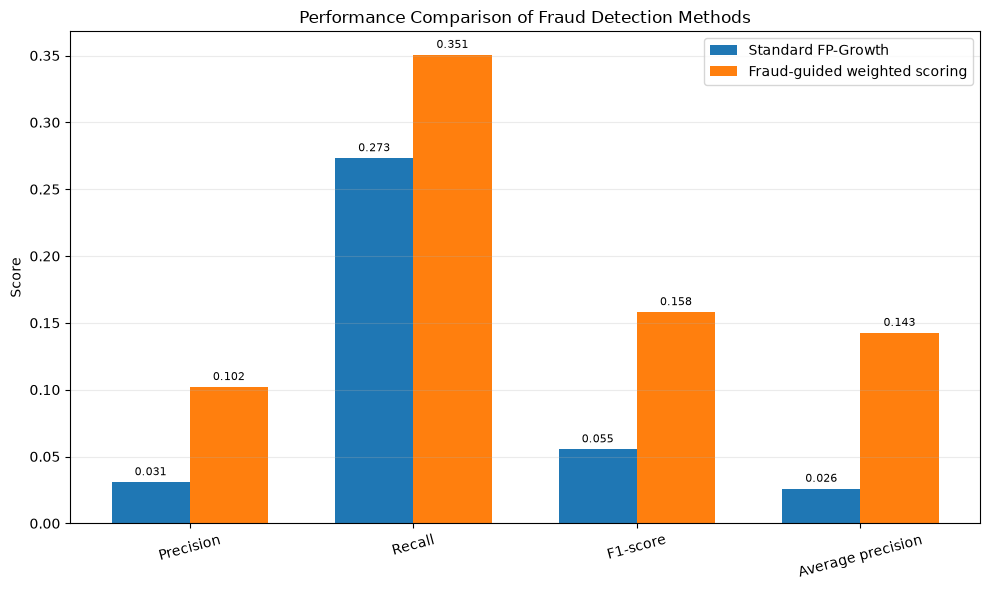

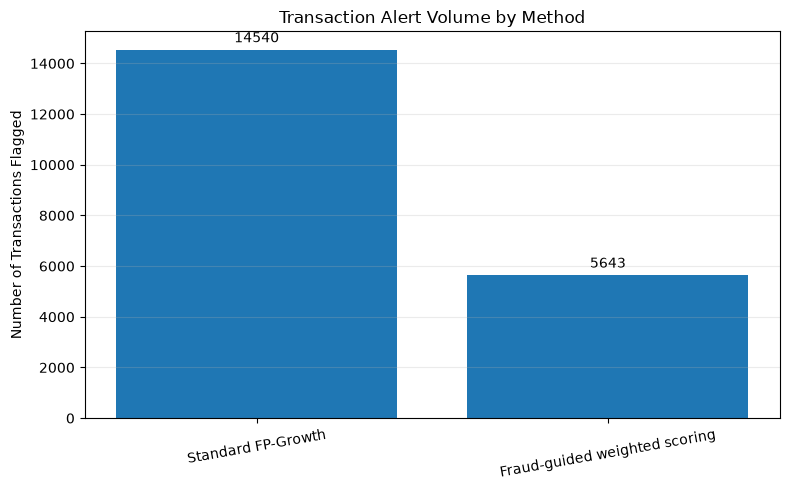

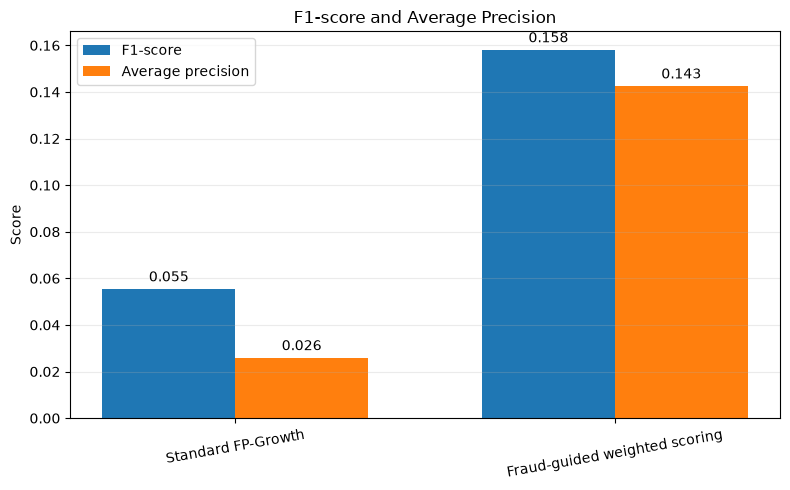

In [113]:

import matplotlib.pyplot as plt
import numpy as np

# Check that comparison results exist
required_columns = [
    "Method", "Precision", "Recall", "F1-score",
    "Average precision", "Flagged"
]

missing = [col for col in required_columns if col not in comparison_df.columns]
if missing:
    raise ValueError(f"Missing columns in comparison_df: {missing}")

# 1. Compare evaluation metrics
metrics = ["Precision", "Recall", "F1-score", "Average precision"]
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

for i, (_, row) in enumerate(comparison_df.iterrows()):
    offset = (i - (len(comparison_df) - 1) / 2) * width
    bars = ax.bar(
        x + offset,
        [row[m] for m in metrics],
        width,
        label=row["Method"]
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

ax.set_title("Performance Comparison of Fraud Detection Methods")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# 2. Compare the number of flagged transactions
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(comparison_df["Method"], comparison_df["Flagged"])

ax.set_title("Transaction Alert Volume by Method")
ax.set_ylabel("Number of Transactions Flagged")
ax.tick_params(axis="x", rotation=10)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# 3. Compare F1-score and average precision
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_df))
width = 0.35

bars1 = ax.bar(
    x - width / 2, comparison_df["F1-score"],
    width, label="F1-score"
)
bars2 = ax.bar(
    x + width / 2, comparison_df["Average precision"],
    width, label="Average precision"
)

ax.set_title("F1-score and Average Precision")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Method"], rotation=10)
ax.legend()
ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


In [114]:
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

In [115]:
arm_df["origin_emptied"] = np.where(
    (arm_df["oldbalanceOrg"] > 0) & (arm_df["newbalanceOrig"] == 0),
    "ORIGIN_EMPTIED", "ORIGIN_NOT_EMPTIED"
)

arm_df["orig_balance_check"] = np.where(
    (arm_df["oldbalanceOrg"] - arm_df["amount"]
     - arm_df["newbalanceOrig"]).abs() > 0.01,
    "ORIG_MISMATCH", "ORIG_OK"
)

arm_df["dest_balance_check"] = np.where(
    (arm_df["oldbalanceDest"] + arm_df["amount"]
     - arm_df["newbalanceDest"]).abs() > 0.01,
    "DEST_MISMATCH", "DEST_OK"
)

new_features = ["origin_emptied", "orig_balance_check", "dest_balance_check"]

# Check each new feature before trusting it: fraud rate (%) per value.
for col in new_features:
    summary = arm_df.groupby(col)["isFraud"].agg(["size", "sum", "mean"])
    summary["mean"] = (summary["mean"] * 100).round(3)
    summary.columns = ["transactions", "fraud_cases", "fraud_rate_%"]
    print(f"\n{col}")
    print(summary)


origin_emptied
                    transactions  fraud_cases  fraud_rate_%
origin_emptied                                             
ORIGIN_EMPTIED           1188074         8012         0.674
ORIGIN_NOT_EMPTIED       1582335          201         0.013

orig_balance_check
                    transactions  fraud_cases  fraud_rate_%
orig_balance_check                                         
ORIG_MISMATCH            2500051           45         0.002
ORIG_OK                   270358         8168         3.021

dest_balance_check
                    transactions  fraud_cases  fraud_rate_%
dest_balance_check                                         
DEST_MISMATCH             628237         4640         0.739
DEST_OK                  2142172         3573         0.167


In [116]:
feature_cols = [
    "type", "amount_category", "balance_change_category",
    "time_category",
    "origin_emptied", "orig_balance_check", "dest_balance_check",
]

experiment_df = arm_df[feature_cols + ["isFraud"]].copy()
for col in feature_cols:
    experiment_df[col] = experiment_df[col].astype(str)
experiment_df["isFraud"] = experiment_df["isFraud"].astype(int)

# 60% mine patterns, 20% choose the threshold, 20% final evaluation.
train_df, temp_df = train_test_split(
    experiment_df, test_size=0.40, random_state=42,
    stratify=experiment_df["isFraud"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42,
    stratify=temp_df["isFraud"]
)

print("Train / validation / test:", len(train_df), len(val_df), len(test_df))
print("Fraud in each:", train_df["isFraud"].sum(),
      val_df["isFraud"].sum(), test_df["isFraud"].sum())

Train / validation / test: 1662245 554082 554082
Fraud in each: 4928 1643 1642


In [117]:
MIN_FRAUD = 5          # at least 5 fraud cases per pattern
MIN_TRANSACTIONS = 30  # and enough transactions to trust the rate

n_train = len(train_df)
base_rate = train_df["isFraud"].mean()
print(f"Training fraud rate: {base_rate * 100:.4f}%")

candidate_rules = []
for size in (2, 3):
    for cols in combinations(feature_cols, size):
        grouped = (
            train_df.groupby(list(cols), observed=True)["isFraud"]
            .agg(["size", "sum"]).reset_index()
        )
        grouped = grouped[
            (grouped["sum"] >= MIN_FRAUD)
            & (grouped["size"] >= MIN_TRANSACTIONS)
        ]
        for _, row in grouped.iterrows():
            count, fraud_count = int(row["size"]), int(row["sum"])
            confidence = fraud_count / count
            lift = confidence / base_rate
            if lift > 1:
                antecedent = tuple((c, str(row[c])) for c in cols)
                candidate_rules.append({
                    "antecedent": antecedent,
                    "pattern": " AND ".join(f"{c}={v}" for c, v in antecedent),
                    "transaction_count": count,
                    "fraud_count": fraud_count,
                    "support": fraud_count / n_train,
                    "confidence": confidence,
                    "lift": lift,
                })

fraud_focused_rules = (
    pd.DataFrame(candidate_rules)
    .sort_values(["lift", "fraud_count", "confidence"], ascending=False)
    .reset_index(drop=True)
)
print("Fraud-focused rules:", len(fraud_focused_rules))
fraud_focused_rules.head(10)

Training fraud rate: 0.2965%
Fraud-focused rules: 336


,antecedent,pattern,transaction_count,fraud_count,support,confidence,lift
0,"((origin_emptied, ORIGIN_EMPTIED), (orig_balan...",origin_emptied=ORIGIN_EMPTIED AND orig_balance...,4811,4811,0.002894,1.0,337.306209
1,"((balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,4451,4451,0.002678,1.0,337.306209
2,"((origin_emptied, ORIGIN_EMPTIED), (orig_balan...",origin_emptied=ORIGIN_EMPTIED AND orig_balance...,2677,2677,0.001610,1.0,337.306209
3,"((type, CASH_OUT), (origin_emptied, ORIGIN_EMP...",type=CASH_OUT AND origin_emptied=ORIGIN_EMPTIE...,2463,2463,0.001482,1.0,337.306209
4,"((type, TRANSFER), (origin_emptied, ORIGIN_EMP...",type=TRANSFER AND origin_emptied=ORIGIN_EMPTIE...,2348,2348,0.001413,1.0,337.306209
5,"((amount_category, AMOUNT_VERY_HIGH), (origin_...",amount_category=AMOUNT_VERY_HIGH AND origin_em...,2301,2301,0.001384,1.0,337.306209
6,"((origin_emptied, ORIGIN_EMPTIED), (orig_balan...",origin_emptied=ORIGIN_EMPTIED AND orig_balance...,2134,2134,0.001284,1.0,337.306209
7,"((time_category, TIME_AFTERNOON), (origin_empt...",time_category=TIME_AFTERNOON AND origin_emptie...,1223,1223,0.000736,1.0,337.306209
8,"((time_category, TIME_MORNING), (origin_emptie...",time_category=TIME_MORNING AND origin_emptied=...,1219,1219,0.000733,1.0,337.306209
9,"((amount_category, AMOUNT_LOW), (origin_emptie...",amount_category=AMOUNT_LOW AND origin_emptied=...,1218,1218,0.000733,1.0,337.306209


In [118]:
def build_rule_table(rules):
    table = []
    for _, r in rules.iterrows():
        evidence = min(
            max(0.0, np.log(max(float(r["lift"]), 1.0)))
            * float(r["confidence"]), 3.0
        )
        table.append((r["antecedent"], len(r["antecedent"]),
                      evidence, r["pattern"]))
    return table


def score_patterns(df, rules, feature_cols):
    """Score each unique feature combination once, then map to rows."""
    result = df.copy()
    rule_table = build_rule_table(rules)

    signatures = list(zip(*(result[c].astype(str) for c in feature_cols)))
    lookup = {}
    for sig in set(signatures):
        values = dict(zip(feature_cols, sig))
        by_size, matched = {}, []
        for antecedent, size, evidence, pattern in rule_table:
            if all(values[c] == v for c, v in antecedent):
                matched.append(pattern)
                by_size[size] = max(by_size.get(size, 0.0), evidence)
        score = 100 * (1 - np.exp(-sum(by_size.values())))
        lookup[sig] = (round(float(score), 2),
                       " | ".join(matched[:5]), len(matched))

    mapped = [lookup[s] for s in signatures]
    result["risk_score"] = [m[0] for m in mapped]
    result["matched_rules"] = [m[1] for m in mapped]
    result["matched_rule_count"] = [m[2] for m in mapped]
    return result


val_scored = score_patterns(val_df, fraud_focused_rules, feature_cols)
test_scored = score_patterns(test_df, fraud_focused_rules, feature_cols)

print("Distinct score values on test data:",
      test_scored["risk_score"].nunique())

Distinct score values on test data: 135


In [119]:
def best_f1_threshold(y_true, scores):
    best_t, best_f1 = 0.0, -1.0
    for t in np.unique(scores):
        pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, pred, zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    return best_t, best_f1


threshold, val_f1 = best_f1_threshold(
    val_scored["isFraud"].to_numpy(), val_scored["risk_score"].to_numpy()
)
print(f"Chosen threshold (validation, best F1): {threshold:.2f} "
      f"(validation F1 = {val_f1:.3f})")

# High = at or above the threshold, Medium = at least half of it.
test_scored["risk_level"] = np.where(
    test_scored["risk_score"] >= threshold, "High",
    np.where(test_scored["risk_score"] >= threshold / 2, "Medium", "Low")
)

Chosen threshold (validation, best F1): 99.75 (validation F1 = 0.987)


In [120]:
y_true = test_scored["isFraud"].to_numpy()
scores = test_scored["risk_score"].to_numpy()
y_pred = (scores >= threshold).astype(int)

test_ap = average_precision_score(y_true, scores)
baseline = y_true.mean()

print(f"Threshold used:     {threshold:.2f}")
print(f"Precision:          {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:             {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:           {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Average Precision:  {test_ap:.4f}")
print(f"Baseline fraud rate:{baseline:.4f}  "
      f"(AP is {test_ap / baseline:.1f}x better than random)")
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

Threshold used:     99.75
Precision:          1.0000
Recall:             0.9726
F1-score:           0.9861
Average Precision:  0.9893
Baseline fraud rate:0.0030  (AP is 333.8x better than random)
Confusion matrix:
 [[552440      0]
 [    45   1597]]


In [121]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

comparison = [{"model": "Rule-based risk score (ours)",
               "average_precision": round(test_ap, 4)}]

# (a) Same categorical features, but a learned model instead of rules.
enc = OneHotEncoder(handle_unknown="ignore")
X_train = enc.fit_transform(train_df[feature_cols])
X_test = enc.transform(test_df[feature_cols])
logreg = LogisticRegression(max_iter=300)
logreg.fit(X_train, train_df["isFraud"])
comparison.append({
    "model": "Logistic regression (same binned features)",
    "average_precision": round(average_precision_score(
        test_df["isFraud"], logreg.predict_proba(X_test)[:, 1]), 4)
})

# (b) Raw numeric values: shows how much binning throws away.
def raw_features(index):
    raw = arm_df.loc[index]
    return pd.DataFrame({
        "is_transfer": (raw["type"] == "TRANSFER").astype(int),
        "amount": raw["amount"],
        "oldbalanceOrg": raw["oldbalanceOrg"],
        "newbalanceOrig": raw["newbalanceOrig"],
        "oldbalanceDest": raw["oldbalanceDest"],
        "newbalanceDest": raw["newbalanceDest"],
        "hour": raw["step"] % 24,
        "orig_error": raw["oldbalanceOrg"] - raw["amount"] - raw["newbalanceOrig"],
        "dest_error": raw["oldbalanceDest"] + raw["amount"] - raw["newbalanceDest"],
    })

gbm = HistGradientBoostingClassifier(random_state=42)
gbm.fit(raw_features(train_df.index), train_df["isFraud"])
comparison.append({
    "model": "Gradient boosting (raw numeric features)",
    "average_precision": round(average_precision_score(
        test_df["isFraud"], gbm.predict_proba(raw_features(test_df.index))[:, 1]), 4)
})

comparison_df = pd.DataFrame(comparison)
comparison_df["baseline_fraud_rate"] = round(baseline, 4)
print(comparison_df.to_string(index=False))

                                     model  average_precision  baseline_fraud_rate
              Rule-based risk score (ours)             0.9893                0.003
Logistic regression (same binned features)             0.9937                0.003
  Gradient boosting (raw numeric features)             0.9907                0.003


In [122]:
# The notebook reads "../data/..." so it lives in a sub-folder of the
# project. The dashboard reads <project root>/outputs, which is
# "../outputs" from the notebook.
output_dir = Path("..") / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

fraud_focused_rules.drop(columns=["antecedent"]).to_csv(
    output_dir / "fraud_focused_rules.csv", index=False)

test_scored.to_csv(output_dir / "fraud_risk_scores.csv", index=False)

test_scored[test_scored["risk_level"] == "High"].sort_values(
    "risk_score", ascending=False
).to_csv(output_dir / "high_risk_transactions.csv", index=False)

comparison_df.to_csv(output_dir / "model_comparison.csv", index=False)

print("Saved to:", output_dir.resolve())
print("Columns:", test_scored.columns.tolist())
print(test_scored["risk_level"].value_counts())

Saved to: D:\projects\machineLearning\outputs
Columns: ['type', 'amount_category', 'balance_change_category', 'time_category', 'origin_emptied', 'orig_balance_check', 'dest_balance_check', 'isFraud', 'risk_score', 'matched_rules', 'matched_rule_count', 'risk_level']
risk_level
Low       541856
Medium     10629
High        1597
Name: count, dtype: int64


In [123]:
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

In [124]:
# Normal transactions reconcile (old balance - amount = new balance).
# Fraudulent ones very often empty the origin account or leave the
# balances inconsistent. Binned amount/time alone cannot see this.

arm_df["origin_emptied"] = np.where(
    (arm_df["oldbalanceOrg"] > 0) & (arm_df["newbalanceOrig"] == 0),
    "ORIGIN_EMPTIED", "ORIGIN_NOT_EMPTIED"
)

arm_df["orig_balance_check"] = np.where(
    (arm_df["oldbalanceOrg"] - arm_df["amount"]
     - arm_df["newbalanceOrig"]).abs() > 0.01,
    "ORIG_MISMATCH", "ORIG_OK"
)

arm_df["dest_balance_check"] = np.where(
    (arm_df["oldbalanceDest"] + arm_df["amount"]
     - arm_df["newbalanceDest"]).abs() > 0.01,
    "DEST_MISMATCH", "DEST_OK"
)

new_features = ["origin_emptied", "orig_balance_check", "dest_balance_check"]

# dest_balance_check uses the destination balance AFTER the transaction.
# That is probably a PaySim simulation artifact and is not reliably known
# when a real bank must approve or block a payment, so the main model
# leaves it out. Set this to True only to reproduce the "with artifact"
# result (the ablation cell at the end compares both).
USE_DEST_CHECK = False

# CHECK each new feature before trusting it: fraud rate (%) per value.
for col in new_features:
    summary = arm_df.groupby(col)["isFraud"].agg(["size", "sum", "mean"])
    summary["mean"] = (summary["mean"] * 100).round(3)
    summary.columns = ["transactions", "fraud_cases", "fraud_rate_%"]
    print(f"\n{col}")
    print(summary)


origin_emptied
                    transactions  fraud_cases  fraud_rate_%
origin_emptied                                             
ORIGIN_EMPTIED           1188074         8012         0.674
ORIGIN_NOT_EMPTIED       1582335          201         0.013

orig_balance_check
                    transactions  fraud_cases  fraud_rate_%
orig_balance_check                                         
ORIG_MISMATCH            2500051           45         0.002
ORIG_OK                   270358         8168         3.021

dest_balance_check
                    transactions  fraud_cases  fraud_rate_%
dest_balance_check                                         
DEST_MISMATCH             628237         4640         0.739
DEST_OK                  2142172         3573         0.167


In [125]:
feature_cols = [
    "type", "amount_category", "balance_change_category",
    "time_category",
    "origin_emptied", "orig_balance_check",
]
if USE_DEST_CHECK:
    feature_cols.append("dest_balance_check")

# Keep dest_balance_check in the table too (used only by the ablation
# cell); the main model mines and scores with feature_cols only.
table_cols = feature_cols + [
    c for c in ["dest_balance_check"] if c not in feature_cols
]
experiment_df = arm_df[table_cols + ["isFraud"]].copy()
for col in table_cols:
    experiment_df[col] = experiment_df[col].astype(str)
experiment_df["isFraud"] = experiment_df["isFraud"].astype(int)

# 60% mine patterns, 20% choose the threshold, 20% final evaluation.
train_df, temp_df = train_test_split(
    experiment_df, test_size=0.40, random_state=42,
    stratify=experiment_df["isFraud"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42,
    stratify=temp_df["isFraud"]
)

print("Train / validation / test:", len(train_df), len(val_df), len(test_df))
print("Fraud in each:", train_df["isFraud"].sum(),
      val_df["isFraud"].sum(), test_df["isFraud"].sum())

Train / validation / test: 1662245 554082 554082
Fraud in each: 4928 1643 1642


In [126]:
MIN_FRAUD = 5          # at least 5 fraud cases per pattern
MIN_TRANSACTIONS = 30  # and enough transactions to trust the rate

n_train = len(train_df)
base_rate = train_df["isFraud"].mean()
print(f"Training fraud rate: {base_rate * 100:.4f}%")

candidate_rules = []
for size in (2, 3):
    for cols in combinations(feature_cols, size):
        grouped = (
            train_df.groupby(list(cols), observed=True)["isFraud"]
            .agg(["size", "sum"]).reset_index()
        )
        grouped = grouped[
            (grouped["sum"] >= MIN_FRAUD)
            & (grouped["size"] >= MIN_TRANSACTIONS)
        ]
        for _, row in grouped.iterrows():
            count, fraud_count = int(row["size"]), int(row["sum"])
            confidence = fraud_count / count
            lift = confidence / base_rate
            if lift > 1:
                antecedent = tuple((c, str(row[c])) for c in cols)
                candidate_rules.append({
                    "antecedent": antecedent,
                    "pattern": " AND ".join(f"{c}={v}" for c, v in antecedent),
                    "transaction_count": count,
                    "fraud_count": fraud_count,
                    "support": fraud_count / n_train,
                    "confidence": confidence,
                    "lift": lift,
                })

fraud_focused_rules = (
    pd.DataFrame(candidate_rules)
    .sort_values(["lift", "fraud_count", "confidence"], ascending=False)
    .reset_index(drop=True)
)
print("Fraud-focused rules:", len(fraud_focused_rules))
fraud_focused_rules.head(10)

Training fraud rate: 0.2965%
Fraud-focused rules: 220


,antecedent,pattern,transaction_count,fraud_count,support,confidence,lift
0,"((origin_emptied, ORIGIN_EMPTIED), (orig_balan...",origin_emptied=ORIGIN_EMPTIED AND orig_balance...,4811,4811,0.002894,1.0,337.306209
1,"((balance_change_category, BALANCE_CHANGE_VERY...",balance_change_category=BALANCE_CHANGE_VERY_HI...,4451,4451,0.002678,1.0,337.306209
2,"((type, CASH_OUT), (origin_emptied, ORIGIN_EMP...",type=CASH_OUT AND origin_emptied=ORIGIN_EMPTIE...,2463,2463,0.001482,1.0,337.306209
3,"((type, TRANSFER), (origin_emptied, ORIGIN_EMP...",type=TRANSFER AND origin_emptied=ORIGIN_EMPTIE...,2348,2348,0.001413,1.0,337.306209
4,"((amount_category, AMOUNT_VERY_HIGH), (origin_...",amount_category=AMOUNT_VERY_HIGH AND origin_em...,2301,2301,0.001384,1.0,337.306209
5,"((time_category, TIME_AFTERNOON), (origin_empt...",time_category=TIME_AFTERNOON AND origin_emptie...,1223,1223,0.000736,1.0,337.306209
6,"((time_category, TIME_MORNING), (origin_emptie...",time_category=TIME_MORNING AND origin_emptied=...,1219,1219,0.000733,1.0,337.306209
7,"((amount_category, AMOUNT_LOW), (origin_emptie...",amount_category=AMOUNT_LOW AND origin_emptied=...,1218,1218,0.000733,1.0,337.306209
8,"((time_category, TIME_EVENING), (origin_emptie...",time_category=TIME_EVENING AND origin_emptied=...,1187,1187,0.000714,1.0,337.306209
9,"((time_category, TIME_NIGHT), (origin_emptied,...",time_category=TIME_NIGHT AND origin_emptied=OR...,1182,1182,0.000711,1.0,337.306209


In [127]:
def build_rule_table(rules):
    table = []
    for _, r in rules.iterrows():
        evidence = min(
            max(0.0, np.log(max(float(r["lift"]), 1.0)))
            * float(r["confidence"]), 3.0
        )
        table.append((r["antecedent"], len(r["antecedent"]),
                      evidence, r["pattern"]))
    return table


def score_patterns(df, rules, feature_cols):
    """Score each unique feature combination once, then map to rows."""
    result = df.copy()
    rule_table = build_rule_table(rules)

    signatures = list(zip(*(result[c].astype(str) for c in feature_cols)))
    lookup = {}
    for sig in set(signatures):
        values = dict(zip(feature_cols, sig))
        by_size, matched = {}, []
        for antecedent, size, evidence, pattern in rule_table:
            if all(values[c] == v for c, v in antecedent):
                matched.append(pattern)
                by_size[size] = max(by_size.get(size, 0.0), evidence)
        score = 100 * (1 - np.exp(-sum(by_size.values())))
        lookup[sig] = (round(float(score), 2),
                       " | ".join(matched[:5]), len(matched))

    mapped = [lookup[s] for s in signatures]
    result["risk_score"] = [m[0] for m in mapped]
    result["matched_rules"] = [m[1] for m in mapped]
    result["matched_rule_count"] = [m[2] for m in mapped]
    return result


val_scored = score_patterns(val_df, fraud_focused_rules, feature_cols)
test_scored = score_patterns(test_df, fraud_focused_rules, feature_cols)

print("Distinct score values on test data:",
      test_scored["risk_score"].nunique())

Distinct score values on test data: 91


In [128]:
def best_f1_threshold(y_true, scores):
    best_t, best_f1 = 0.0, -1.0
    for t in np.unique(scores):
        pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, pred, zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    return best_t, best_f1


threshold, val_f1 = best_f1_threshold(
    val_scored["isFraud"].to_numpy(), val_scored["risk_score"].to_numpy()
)
print(f"Chosen threshold (validation, best F1): {threshold:.2f} "
      f"(validation F1 = {val_f1:.3f})")

# High = at or above the threshold, Medium = at least half of it.
test_scored["risk_level"] = np.where(
    test_scored["risk_score"] >= threshold, "High",
    np.where(test_scored["risk_score"] >= threshold / 2, "Medium", "Low")
)

Chosen threshold (validation, best F1): 99.75 (validation F1 = 0.987)


In [129]:
y_true = test_scored["isFraud"].to_numpy()
scores = test_scored["risk_score"].to_numpy()
y_pred = (scores >= threshold).astype(int)

test_ap = average_precision_score(y_true, scores)
baseline = y_true.mean()

print(f"Threshold used:     {threshold:.2f}")
print(f"Precision:          {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:             {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:           {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Average Precision:  {test_ap:.4f}")
print(f"Baseline fraud rate:{baseline:.4f}  "
      f"(AP is {test_ap / baseline:.1f}x better than random)")
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

Threshold used:     99.75
Precision:          1.0000
Recall:             0.9726
F1-score:           0.9861
Average Precision:  0.9898
Baseline fraud rate:0.0030  (AP is 334.0x better than random)
Confusion matrix:
 [[552440      0]
 [    45   1597]]


In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

comparison = [{"model": "Rule-based risk score (ours)",
               "average_precision": round(test_ap, 4)}]

# (a) Same categorical features, but a learned model instead of rules.
enc = OneHotEncoder(handle_unknown="ignore")
X_train = enc.fit_transform(train_df[feature_cols])
X_test = enc.transform(test_df[feature_cols])
logreg = LogisticRegression(max_iter=300)
logreg.fit(X_train, train_df["isFraud"])
comparison.append({
    "model": "Logistic regression (same binned features)",
    "average_precision": round(average_precision_score(
        test_df["isFraud"], logreg.predict_proba(X_test)[:, 1]), 4)
})

# (b) Raw numeric values: shows how much binning throws away.
def raw_features(index):
    raw = arm_df.loc[index]
    cols = {
        "is_transfer": (raw["type"] == "TRANSFER").astype(int),
        "amount": raw["amount"],
        "oldbalanceOrg": raw["oldbalanceOrg"],
        "newbalanceOrig": raw["newbalanceOrig"],
        "oldbalanceDest": raw["oldbalanceDest"],
        "hour": raw["step"] % 24,
        "orig_error": raw["oldbalanceOrg"] - raw["amount"] - raw["newbalanceOrig"],
    }
    if USE_DEST_CHECK:   # keep the comparison fair with the main model
        cols["newbalanceDest"] = raw["newbalanceDest"]
        cols["dest_error"] = (
            raw["oldbalanceDest"] + raw["amount"] - raw["newbalanceDest"]
        )
    return pd.DataFrame(cols)

gbm = HistGradientBoostingClassifier(random_state=42)
gbm.fit(raw_features(train_df.index), train_df["isFraud"])
comparison.append({
    "model": "Gradient boosting (raw numeric features)",
    "average_precision": round(average_precision_score(
        test_df["isFraud"], gbm.predict_proba(raw_features(test_df.index))[:, 1]), 4)
})

comparison_df = pd.DataFrame(comparison)
comparison_df["baseline_fraud_rate"] = round(baseline, 4)
print(comparison_df.to_string(index=False))

                                     model  average_precision  baseline_fraud_rate
              Rule-based risk score (ours)             0.9898                0.003
Logistic regression (same binned features)             0.9933                0.003
  Gradient boosting (raw numeric features)             0.9276                0.003


In [131]:
# The notebook reads "../data/..." so it lives in a sub-folder of the
# project. The dashboard reads <project root>/outputs, which is
# "../outputs" from the notebook. (Path("outputs") would have saved
# into the notebook's own folder, where the dashboard cannot see it.)
output_dir = Path("..") / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

fraud_focused_rules.drop(columns=["antecedent"]).to_csv(
    output_dir / "fraud_focused_rules.csv", index=False)

if not USE_DEST_CHECK:   # keep the saved file consistent with the model
    test_scored = test_scored.drop(columns=["dest_balance_check"],
                                   errors="ignore")

test_scored.to_csv(output_dir / "fraud_risk_scores.csv", index=False)

test_scored[test_scored["risk_level"] == "High"].sort_values(
    "risk_score", ascending=False
).to_csv(output_dir / "high_risk_transactions.csv", index=False)

comparison_df.to_csv(output_dir / "model_comparison.csv", index=False)

print("Saved to:", output_dir.resolve())
print("Columns:", test_scored.columns.tolist())
print(test_scored["risk_level"].value_counts())

Saved to: D:\projects\machineLearning\outputs
Columns: ['type', 'amount_category', 'balance_change_category', 'time_category', 'origin_emptied', 'orig_balance_check', 'isFraud', 'risk_score', 'matched_rules', 'matched_rule_count', 'risk_level']
risk_level
Low       542289
Medium     10196
High        1597
Name: count, dtype: int64


In [132]:
def run_variant(feats, label):
    rows = []
    for size in (2, 3):
        for cols in combinations(feats, size):
            g = (train_df.groupby(list(cols), observed=True)["isFraud"]
                 .agg(["size", "sum"]).reset_index())
            g = g[(g["sum"] >= MIN_FRAUD) & (g["size"] >= MIN_TRANSACTIONS)]
            for _, row in g.iterrows():
                conf = row["sum"] / row["size"]
                lift = conf / base_rate
                if lift > 1:
                    ant = tuple((c, str(row[c])) for c in cols)
                    rows.append({
                        "antecedent": ant,
                        "pattern": " AND ".join(f"{c}={v}" for c, v in ant),
                        "confidence": conf, "lift": lift,
                    })
    if not rows:
        return {"features": label, "precision": 0, "recall": 0,
                "f1": 0, "average_precision": 0}
    rules_df = pd.DataFrame(rows)
    v = score_patterns(val_df, rules_df, feats)
    t = score_patterns(test_df, rules_df, feats)
    thr, _ = best_f1_threshold(v["isFraud"].to_numpy(),
                               v["risk_score"].to_numpy())
    y = t["isFraud"].to_numpy()
    pred = (t["risk_score"].to_numpy() >= thr).astype(int)
    return {
        "features": label,
        "precision": round(precision_score(y, pred, zero_division=0), 3),
        "recall": round(recall_score(y, pred, zero_division=0), 3),
        "f1": round(f1_score(y, pred, zero_division=0), 3),
        "average_precision": round(
            average_precision_score(y, t["risk_score"].to_numpy()), 3),
    }

base4 = ["type", "amount_category", "balance_change_category", "time_category"]

ablation = pd.DataFrame([
    run_variant(base4 + ["origin_emptied", "orig_balance_check",
                         "dest_balance_check"],
                "All 7 features (incl. dest_balance_check)"),
    run_variant(base4 + ["origin_emptied", "orig_balance_check"],
                "6 features, no dest_balance_check (main model)"),
    run_variant(base4 + ["origin_emptied"],
                "Original 4 + origin_emptied only"),
    run_variant(base4, "Original 4 features only"),
])
print(ablation.to_string(index=False))

                                      features  precision  recall    f1  average_precision
     All 7 features (incl. dest_balance_check)      1.000   0.973 0.986              0.989
6 features, no dest_balance_check (main model)      1.000   0.973 0.986              0.990
              Original 4 + origin_emptied only      0.373   0.225 0.280              0.134
                      Original 4 features only      0.304   0.225 0.258              0.133
